# Análisis exploratorio de datos (EDA)
### Proyecto de Aprendizaje Automático · Encuesta de salud del consorcio de atención primaria

**Objetivo del notebook.** Entender en profundidad la estructura, la calidad y las relaciones del conjunto `proy_diabetes_dev.csv` para fundamentar las decisiones de preprocesado de las tres líneas de trabajo:

| Línea | Tarea | Variable objetivo |
|---|---|---|
| 1 | Clusterización de perfiles de paciente | — |
| 2 | Clasificación (cribado) | `diabetes` (sí/no) |
| 3 | Regresión (carga de enfermedad) | `dias_salud_fisica_mala` (0–30) |

Cada sección termina con un bloque **Hallazgos** que resume la interpretación y su implicación para el modelado. Las afirmaciones se apoyan en tests estadísticos **y tamaños del efecto**: con n = 12.750 casi cualquier diferencia es "significativa", así que lo relevante es su magnitud.

## Resumen ejecutivo

1. **Calidad de datos.** 12.750 registros × 29 columnas. 7 columnas son PII ofuscada y 1 es de gestión interna (`usuario_alta_datos`), que se demuestra irrelevante (χ² p = 0,48; V de Cramér = 0,00). Quedan **18 predictores + 2 objetivos**.
2. **Codificaciones inconsistentes** en 4 variables binarias (`fumador`, `actividad_fisica`, `consume_fruta`, `dificultad_caminar`): hasta 8 representaciones distintas (`si`, `SI`, `True`, `1.0`…), en torno a 1 de cada 4 registros. Se unifican a 0/1 sin pérdida de información.
3. **Valores ausentes** en el 8 % de las filas, con dos patrones estructurados e independientes entre sí: un **bloque** de 376 filas sin los 4 hábitos anteriores y un **patrón monótono anidado** (`salud_general` ⊂ `imc` + salud mental ⊂ `nivel_ingresos`), típico de abandono del cuestionario. No hay diferencias relevantes entre filas con y sin nulos (todos los p > 0,05; |δ| < 0,06): compatible con MCAR → **imputación simple dentro del pipeline**, ajustada solo en train.
4. **`diabetes`** está **remuestreada** al 33 %: útil para entrenar, pero las probabilidades del modelo **no son poblacionales**. Los predictores más asociados son la salud autopercibida (V = 0,40), la carga de factores de riesgo cardiovascular (V = 0,38), el IMC (δ de Cliff = 0,37), la hipertensión (V = 0,34) y la edad. La prevalencia pasa del 17 % con IMC normal al 61 % en obesidad III.
5. **`dias_salud_fisica_mala`** es **cero-inflada y bimodal**: 60 % de ceros, 9 % en el máximo (30), varianza 18 veces la media y *heaping* en múltiplos de 5. No es una variable continua ordinaria → conviene MAE, modelos de dos partes o Tweedie/Poisson.
6. El mejor predictor de los días de mala salud física es la **salud autopercibida** (ρ = 0,50; de 0,9 días de media en "excelente" a 23,3 en "mala"), seguida de `dificultad_caminar` y los días de mala salud mental.
7. Existe un **gradiente socioeconómico** claro: la prevalencia de diabetes va del 52 % con ingresos < 10k al 20 % con > 75k.
8. Para clusterizar, el PCA revela un eje principal de **"carga de enfermedad"** (salud percibida, dificultad para caminar, días de mala salud, diabetes) y un segundo eje que opone un perfil **cardiometabólico de mayor edad** a uno **más joven con malestar psicológico**. Los datos forman un **continuo** más que grupos separados, y las variables binarias dominan las distancias: hay que elegir con cuidado variables y métrica para obtener perfiles interpretables.
9. No hay **multicolinealidad** problemática entre los predictores originales (VIF máx. = 1,7).

### Índice
1. [Carga y diccionario de datos](#1)
2. [Calidad de datos](#2)
3. [Valores ausentes](#3)
4. [Análisis univariante](#4)
5. [Variables objetivo](#5)
6. [Relación con `diabetes`](#6)
7. [Relación con `dias_salud_fisica_mala`](#7)
8. [Análisis multivariante](#8)
9. [Exploración orientada a clustering](#9)
10. [Conclusiones y decisiones de preprocesado](#10)

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from sklearn.decomposition import PCA
from sklearn.feature_selection import mutual_info_classif, mutual_info_regression
from sklearn.manifold import TSNE
from statsmodels.stats.outliers_influence import variance_inflation_factor

sys.path.append(str(Path.cwd().parent))
from src import eda_utils as eu
from src import preprocesamiento as pp

warnings.filterwarnings("ignore", category=FutureWarning)
eu.configurar_estilo()

<a id="1"></a>
## 1. Carga y diccionario de datos

In [2]:
crudo = pp.cargar_datos()
print(f"Dimensiones: {crudo.shape[0]:,} filas × {crudo.shape[1]} columnas")
crudo.head()

Dimensiones: 12,750 filas × 29 columnas


,id_paciente_proy,dni,nombre,apellidos,direccion,telefono,email,num_historia_clinica,presion_alta,colesterol_alto,chequeo_colesterol_5a,imc,fumador,ictus,enfermedad_cardiaca,actividad_fisica,consume_fruta,consume_verdura,consumo_alcohol_alto,salud_general,dias_salud_mental_mala,dias_salud_fisica_mala,dificultad_caminar,sexo,grupo_edad,nivel_educativo,nivel_ingresos,diabetes,usuario_alta_datos
0,90,9002b707403a13310b63559f1424a2a3,55f15684574c8895c4234fb7987d23cb,cde3522f31388e7cfe8663f173e07bc0,5a0d0afae7c4f2b727332e30663222ee,16a767cbb4bbeb01d995a44e320ac087,9ba86cc234d2bc2067fec10ff049a7aa,da2d03b68a2745843ee1060fc98a346c,si,si,si,NaN,no,no,no,si,si,si,no,NaN,NaN,0,no,hombre,55-59,secundaria,NaN,no,admin
1,2443,162319c0551225e9fe2c5da7b6d52e71,30c9a0e33312b54775ee3fc1d34483d7,86996ec928b462ee8f0343ffbe0f82b1,c16b76aaa2d4abca01b67816003c67a2,7176ee8d6dae058edcb75528c0d74951,84077d4793dc2403eb934b9ad8490187,97b18957d6589adf7a7fd119a8959ef8,si,si,si,41.000,NO,no,no,NO,SI,si,no,buena,0.000,0,SI,mujer,80+,secundaria,10-15k,si,us_admision_1
2,11061,e7fee47d66a627a2bd11e1abcb6fc71d,fa9b67a5f04ab381a655ce11f71ede16,1de54ad005a1c2e875664eb4e3e3b0e3,159882b4d4946b7ae0cb163e731af530,ffb6bb2a2189224fd204a4e7015ddac1,674f85328d69d9c64b29aa1f05fe42d1,2e2922cdd75430e622f1540f5614679f,si,si,si,30.000,no,no,no,si,no,si,no,muy buena,0.000,0,no,hombre,60-64,secundaria,35-50k,si,us_admision_1
3,4777,ed14f2ce7d014c27d4f65190e7a9f2bd,1a25cd782eafac0e7613b53daab84118,8f6a795e173f85e9eef5b15d2ca9d0ce,e6b9d22501402431c452cdc8bdfcfbc0,ab92997db67891fd459f7f655cf8154a,8f7a38fcc02a52059f111b68702bf21b,ba5bbe61c14e46778133748b770d873b,si,si,si,36.000,si,no,no,no,si,si,no,buena,0.000,2,si,mujer,60-64,titulado superior,>75k,si,us_admision_2
4,14534,7b15ec3e056f5f2f6edaa83c77201f00,b712489fdcf4c8946982dc81e192f344,c068e6fc1dd7f60ea956fa46d18fbc3c,30fc1cb6ccc6e5f6d9dc154d1df9c527,6b12d7e59d47d9bd0a7003ab8b29eb74,75c31956bcd1af3079a6bb6f4970ac8d,9c5187719c6a3b5c27e1c94ff4d515f6,no,si,si,30.000,no,no,no,si,no,no,no,muy buena,5.000,30,si,hombre,50-54,secundaria,50-75k,no,us_admision_1


In [3]:
DESCRIPCION = {
    "id_paciente_proy": "Identificador del registro en la extracción",
    "dni": "DNI (ofuscado)", "nombre": "Nombre (ofuscado)", "apellidos": "Apellidos (ofuscado)",
    "direccion": "Dirección (ofuscado)", "telefono": "Teléfono (ofuscado)", "email": "Email (ofuscado)",
    "num_historia_clinica": "Nº de historia clínica (ofuscado)",
    "presion_alta": "Diagnóstico de hipertensión", "colesterol_alto": "Diagnóstico de colesterol alto",
    "chequeo_colesterol_5a": "Control de colesterol en los últimos 5 años",
    "imc": "Índice de masa corporal (kg/m²)", "fumador": "Ha fumado ≥100 cigarrillos en su vida",
    "ictus": "Ha sufrido un ictus", "enfermedad_cardiaca": "Cardiopatía coronaria o infarto",
    "actividad_fisica": "Actividad física en los últimos 30 días", "consume_fruta": "Consume fruta a diario",
    "consume_verdura": "Consume verdura a diario", "consumo_alcohol_alto": "Consumo elevado de alcohol",
    "salud_general": "Salud autopercibida (excelente → mala)",
    "dias_salud_mental_mala": "Días de mala salud mental en el último mes (0–30)",
    "dias_salud_fisica_mala": "Días de mala salud física en el último mes (0–30)",
    "dificultad_caminar": "Dificultad seria para caminar o subir escaleras",
    "sexo": "Sexo", "grupo_edad": "Grupo de edad (13 tramos)", "nivel_educativo": "Nivel educativo (6 niveles)",
    "nivel_ingresos": "Ingresos anuales del hogar (8 tramos)", "diabetes": "Diagnóstico de diabetes",
    "usuario_alta_datos": "Usuario que registró el dato",
}


def rol(col):
    if col in pp.COLS_PII:
        return "PII (descartar)"
    if col in pp.COLS_GESTION or col == pp.COL_ID:
        return "Gestión / identificador"
    if col in (pp.TARGET_CLASIF, pp.TARGET_REGR):
        return "Objetivo"
    return "Predictor"


def tipo(col):
    if col in ("imc", "dias_salud_mental_mala", "dias_salud_fisica_mala"):
        return "Numérica"
    if col in pp.MAPAS_ORDINALES:
        return "Ordinal"
    if col in pp.COLS_BINARIAS_ORIGINALES or col == "sexo":
        return "Binaria"
    return "Texto / ID"


diccionario = pd.DataFrame(
    {
        "descripcion": DESCRIPCION,
        "tipo": {c: tipo(c) for c in crudo.columns},
        "rol": {c: rol(c) for c in crudo.columns},
        "valores_distintos": crudo.nunique(),
        "pct_nulos": crudo.isna().mean().mul(100).round(1),
        "ejemplo": crudo.iloc[1],
    }
).loc[crudo.columns]
diccionario.style.format({"pct_nulos": "{:.1f} %"}).background_gradient(subset="pct_nulos", cmap="Oranges")

,descripcion,tipo,rol,valores_distintos,pct_nulos,ejemplo
id_paciente_proy,Identificador del registro en la extracción,Texto / ID,Gestión / identificador,12750,0.0 %,2443
dni,DNI (ofuscado),Texto / ID,PII (descartar),12750,0.0 %,162319c0551225e9fe2c5da7b6d52e71
nombre,Nombre (ofuscado),Texto / ID,PII (descartar),12750,0.0 %,30c9a0e33312b54775ee3fc1d34483d7
apellidos,Apellidos (ofuscado),Texto / ID,PII (descartar),12750,0.0 %,86996ec928b462ee8f0343ffbe0f82b1
direccion,Dirección (ofuscado),Texto / ID,PII (descartar),12750,0.0 %,c16b76aaa2d4abca01b67816003c67a2
telefono,Teléfono (ofuscado),Texto / ID,PII (descartar),12750,0.0 %,7176ee8d6dae058edcb75528c0d74951
email,Email (ofuscado),Texto / ID,PII (descartar),12750,0.0 %,84077d4793dc2403eb934b9ad8490187
num_historia_clinica,Nº de historia clínica (ofuscado),Texto / ID,PII (descartar),12750,0.0 %,97b18957d6589adf7a7fd119a8959ef8
presion_alta,Diagnóstico de hipertensión,Binaria,Predictor,2,0.0 %,si
colesterol_alto,Diagnóstico de colesterol alto,Binaria,Predictor,2,0.0 %,si


In [4]:
diccionario["rol"].value_counts().to_frame("nº columnas")

,nº columnas
rol,
Predictor,18
PII (descartar),7
Gestión / identificador,2
Objetivo,2


**Hallazgos**
- El archivo mezcla tres tipos de columnas: **8 de identificación/PII**, **1 de gestión** y **20 de contenido** (18 predictores y 2 objetivos), tal y como advierte el enunciado.
- Las columnas PII tienen un valor distinto por fila (son *hashes*), por lo que no generalizan y además están sujetas a protección de datos: **se eliminan en el primer paso del preprocesado**.
- Los predictores son casi todos **binarios u ordinales**; solo `imc` y los días de mala salud son numéricos. Esto condiciona las medidas de asociación (χ²/V de Cramér, Spearman) y el escalado.

<a id="2"></a>
## 2. Calidad de datos

### 2.1 ¿Aporta algo `usuario_alta_datos`?
Es una columna de gestión interna (quién tecleó el registro). Si estuviera asociada a los objetivos sería una **fuga de información** (p. ej. un usuario que solo registra pacientes diabéticos); si no, es ruido. Lo comprobamos.

In [5]:
usuario = crudo["usuario_alta_datos"]
diab = crudo["diabetes"].map({"si": 1, "no": 0})
tabla_usuario = pd.crosstab(usuario, diab, normalize="index").rename(columns=eu.ETIQUETAS_DIABETES)
tabla_usuario["n"] = usuario.value_counts()
display(tabla_usuario.style.format({"Sin diabetes": "{:.1%}", "Con diabetes": "{:.1%}"}))

res_diab = eu.test_chi2(usuario, diab)
res_dias = eu.test_kruskal(crudo, "usuario_alta_datos", "dias_salud_fisica_mala")
print(f"usuario vs diabetes             → χ² = {res_diab['chi2']:.2f}, p = {res_diab['p_valor']:.3f}, V de Cramér = {res_diab['v_cramer']:.3f}")
print(f"usuario vs dias_salud_fisica_mala → H = {res_dias['H']:.2f}, p = {res_dias['p_valor']:.3f}, ε² = {res_dias['epsilon2']:.5f}")

diabetes,Sin diabetes,Con diabetes,n
usuario_alta_datos,,,
admin,65.6%,34.4%,3166
enfermeria.turno_a,67.2%,32.8%,3154
us_admision_1,67.0%,33.0%,3233
us_admision_2,67.2%,32.8%,3197


usuario vs diabetes             → χ² = 2.45, p = 0.485, V de Cramér = 0.000
usuario vs dias_salud_fisica_mala → H = 0.54, p = 0.911, ε² = 0.00004


### 2.2 Codificaciones inconsistentes en variables binarias

In [6]:
binarias_crudas = [c for c in pp.COLS_BINARIAS_ORIGINALES] + ["sexo"]
resumen_cod = pd.DataFrame(
    {
        "nº codificaciones": crudo[binarias_crudas].nunique(),
        "valores": crudo[binarias_crudas].apply(lambda s: sorted(s.dropna().astype(str).unique())),
        "% registros fuera de si/no": crudo[binarias_crudas]
        .apply(lambda s: (~s.isin(["si", "no", "hombre", "mujer"]) & s.notna()).mean() * 100)
        .round(1),
    }
).sort_values("nº codificaciones", ascending=False)
resumen_cod

,nº codificaciones,valores,% registros fuera de si/no
fumador,8,"[0.0, 1.0, False, NO, SI, True, no, si]",25.100
consume_fruta,8,"[0.0, 1.0, False, NO, SI, True, no, si]",25.100
dificultad_caminar,8,"[0.0, 1.0, False, NO, SI, True, no, si]",25.100
actividad_fisica,8,"[0.0, 1.0, False, NO, SI, True, no, si]",25.100
presion_alta,2,"[no, si]",0.000
ictus,2,"[no, si]",0.000
chequeo_colesterol_5a,2,"[no, si]",0.000
colesterol_alto,2,"[no, si]",0.000
enfermedad_cardiaca,2,"[no, si]",0.000
consume_verdura,2,"[no, si]",0.000


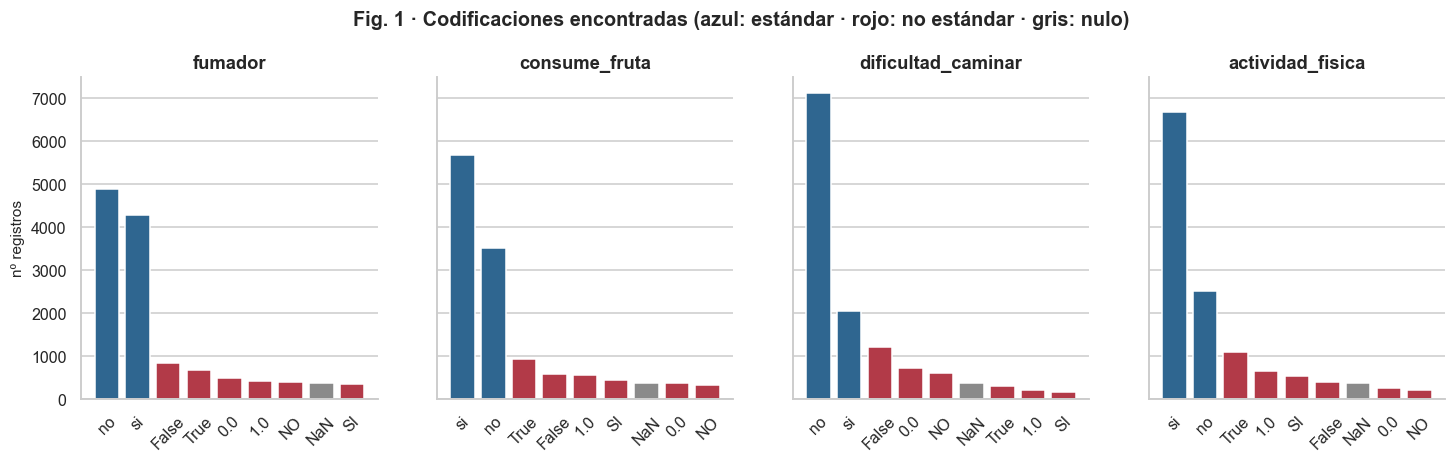

In [7]:
sucias = resumen_cod.index[resumen_cod["nº codificaciones"] > 2].tolist()
fig, axes = plt.subplots(1, len(sucias), figsize=(16, 3.8), sharey=True)
for ax, col in zip(axes, sucias):
    conteo = crudo[col].fillna("NaN").astype(str).value_counts()
    colores = [eu.GRIS if v == "NaN" else (eu.AZUL if v in ("si", "no") else eu.ROJO) for v in conteo.index]
    ax.bar(conteo.index, conteo.values, color=colores)
    ax.set_title(col)
    ax.tick_params(axis="x", rotation=45)
axes[0].set_ylabel("nº registros")
fig.suptitle("Fig. 1 · Codificaciones encontradas (azul: estándar · rojo: no estándar · gris: nulo)", y=1.04)
eu.guardar_figura(fig, "fig01_codificaciones_binarias")
plt.show()

In [8]:
# Antes / después de la normalización (ver pp.normalizar_binaria)
antes_despues = {
    col: pd.crosstab(crudo[col].fillna("NaN").astype(str), pp.normalizar_binaria(crudo[col]).fillna(-1).map({1: "1", 0: "0", -1: "NaN"}))
    for col in sucias
}
antes_despues["fumador"]

fumador,0,1,NaN
fumador,,,
0.0,501,0,0
1.0,0,428,0
False,831,0,0
NO,403,0,0
NaN,0,0,376
SI,0,359,0
True,0,678,0
no,4895,0,0
si,0,4279,0


### 2.3 Duplicados y coherencia lógica

In [9]:
datos = pp.preparar(crudo)  # limpieza determinista + variables derivadas (src/preprocesamiento.py)
sin_id = crudo.drop(columns=pp.COLS_PII + pp.COLS_GESTION + [pp.COL_ID])
print(f"IDs duplicados:                                  {crudo[pp.COL_ID].duplicated().sum()}")
print(f"Filas idénticas en todas las variables de contenido: {sin_id.duplicated().sum()}")

coherencia = pd.Series(
    {
        "Salud 'excelente' y 30 días de mala salud física": ((datos.salud_general == 1) & (datos.dias_salud_fisica_mala == 30)).sum(),
        "Salud 'excelente' y ≥15 días de mala salud física": ((datos.salud_general == 1) & (datos.dias_salud_fisica_mala >= 15)).sum(),
        "Colesterol alto sin control en 5 años": ((datos.colesterol_alto == 1) & (datos.chequeo_colesterol_5a == 0)).sum(),
        "IMC < 15 (delgadez extrema)": (datos.imc < 15).sum(),
        "IMC ≥ 60": (datos.imc >= 60).sum(),
        "Días fuera de [0, 30]": ((crudo.dias_salud_fisica_mala > 30) | (crudo.dias_salud_mental_mala > 30)).sum(),
    },
    name="nº registros",
).to_frame()
coherencia

IDs duplicados:                                  0
Filas idénticas en todas las variables de contenido: 82


,nº registros
Salud 'excelente' y 30 días de mala salud física,20
Salud 'excelente' y ≥15 días de mala salud física,35
Colesterol alto sin control en 5 años,69
IMC < 15 (delgadez extrema),2
IMC ≥ 60,51
"Días fuera de [0, 30]",0


**Hallazgos**
- `usuario_alta_datos` **no está asociada** con ninguno de los dos objetivos (V de Cramér ≈ 0, ε² ≈ 0) y las codificaciones sucias aparecen por igual con todos los usuarios. Es una columna de gestión sin valor predictivo y sin riesgo de fuga → **se elimina**.
- Cuatro binarias presentan hasta **8 codificaciones** (`si/no`, `SI/NO`, `True/False`, `1.0/0.0`), con alrededor de un 25 % de registros fuera del formato estándar. La correspondencia es inequívoca, así que **se unifican a 0/1** (`pp.normalizar_binaria`) sin perder información. La función acepta además variantes razonables no vistas (`sí`, `yes`, …) y convierte lo irreconocible en nulo, para que una instancia nueva nunca rompa la API.
- No hay IDs duplicados. Las 82 filas idénticas (0,6 %) son esperables con 18 variables casi todas discretas (dos pacientes distintos pueden responder igual) → **se mantienen**.
- Las incoherencias lógicas son **escasas** y clínicamente posibles (un paciente puede valorar su salud como excelente pese a una lesión puntual; el colesterol alto pudo diagnosticarse hace más de 5 años). Los IMC extremos (≥ 60) son raros pero plausibles en obesidad mórbida. **No se eliminan**; solo se anularían valores físicamente imposibles (IMC fuera de [10, 100], días fuera de [0, 30]), que en este archivo no aparecen.

<a id="3"></a>
## 3. Valores ausentes

In [10]:
nulos = crudo.isna().sum()
nulos = nulos[nulos > 0].sort_values(ascending=False)
tabla_nulos = pd.DataFrame({"nulos": nulos, "%": (nulos / len(crudo) * 100).round(2)})
print(f"Filas con al menos un nulo: {crudo.isna().any(axis=1).sum():,} ({crudo.isna().any(axis=1).mean():.1%})")
tabla_nulos

Filas con al menos un nulo: 1,015 (8.0%)


,nulos,%
nivel_ingresos,657,5.150
imc,397,3.110
dias_salud_mental_mala,397,3.110
fumador,376,2.950
consume_fruta,376,2.950
actividad_fisica,376,2.950
dificultad_caminar,376,2.950
salud_general,267,2.090


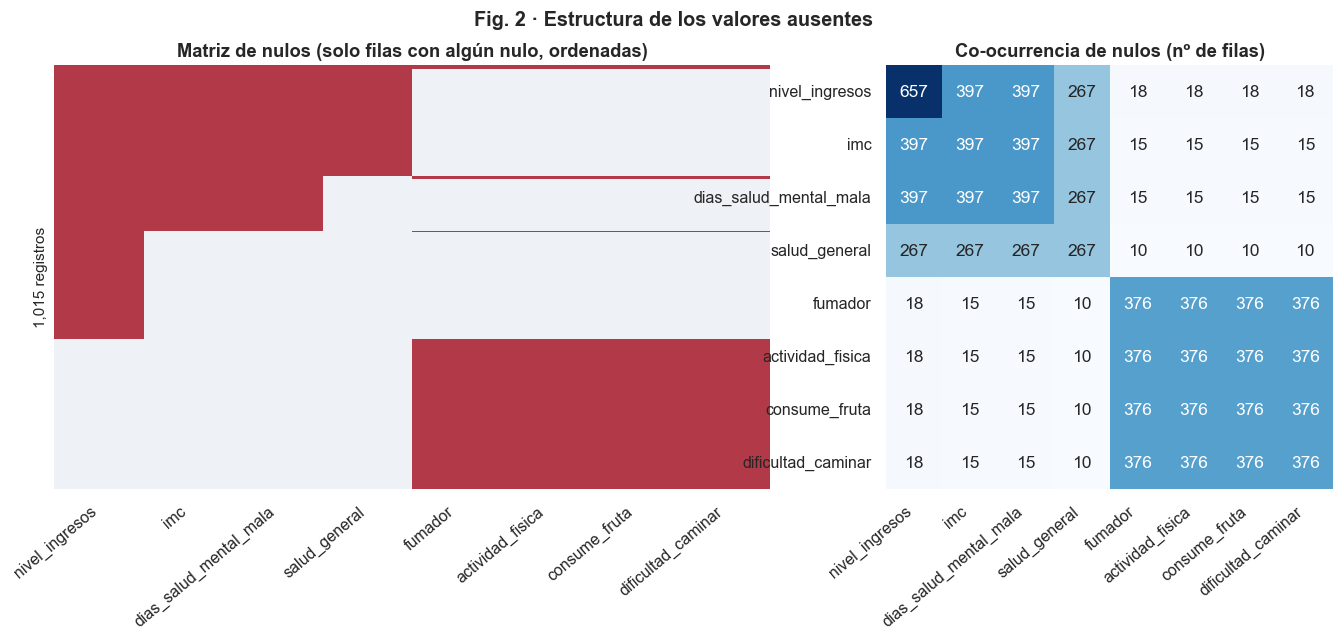

In [11]:
cols_nulos = ["nivel_ingresos", "imc", "dias_salud_mental_mala", "salud_general", "fumador", "actividad_fisica", "consume_fruta", "dificultad_caminar"]
filas_con_nulo = crudo.loc[crudo[cols_nulos].isna().any(axis=1), cols_nulos]
orden = filas_con_nulo.isna().astype(int).sort_values(cols_nulos, ascending=False).index

fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [1.6, 1]})
sns.heatmap(filas_con_nulo.loc[orden].isna(), cbar=False, cmap=["#EEF2F6", eu.ROJO], ax=axes[0], yticklabels=False)
axes[0].set_title("Matriz de nulos (solo filas con algún nulo, ordenadas)")
axes[0].set_ylabel(f"{len(filas_con_nulo):,} registros")

coocurrencia = crudo[cols_nulos].isna().astype(int)
coocurrencia = coocurrencia.T @ coocurrencia
sns.heatmap(coocurrencia, annot=True, fmt="d", cmap=eu.CMAP_SECUENCIAL, ax=axes[1], cbar=False)
axes[1].set_title("Co-ocurrencia de nulos (nº de filas)")
for ax in axes:
    ax.grid(False)
    ax.tick_params(axis="x", rotation=40)
    for lbl in ax.get_xticklabels():
        lbl.set_ha("right")
fig.suptitle("Fig. 2 · Estructura de los valores ausentes")
eu.guardar_figura(fig, "fig02_valores_ausentes")
plt.show()

**¿Qué mecanismo genera los nulos?** Si los nulos fueran MCAR (*Missing Completely At Random*), las filas con nulo no deberían diferir del resto. Comparamos, para cada bloque de nulos, variables completas (demográficas, clínicas y ambos objetivos).

In [12]:
bloques = {
    "Hábitos (376)": datos["falta_habitos"] == 1,
    "Ingresos (657)": datos["nivel_ingresos"].isna(),
    "IMC + salud mental (397)": datos["falta_imc"] == 1,
    "Salud general (267)": datos["salud_general"].isna(),
}
# Comprobación del anidamiento observado en la Fig. 2
anidado = (datos.loc[datos.salud_general.isna(), "falta_imc"].all(), datos.loc[datos.falta_imc == 1, "nivel_ingresos"].isna().all())
print(f"¿salud_general nulo ⇒ imc nulo? {anidado[0]} · ¿imc nulo ⇒ ingresos nulo? {anidado[1]}")
esperado = (datos.falta_habitos == 1).mean() * datos.nivel_ingresos.isna().mean() * len(datos)
observado = ((datos.falta_habitos == 1) & datos.nivel_ingresos.isna()).sum()
print(f"Solape hábitos × ingresos: observado = {observado}, esperado si fueran independientes = {esperado:.1f}")
comparar = ["grupo_edad", "es_hombre", "nivel_educativo", "presion_alta", "colesterol_alto", "diabetes", "dias_salud_fisica_mala"]
filas = []
for bloque, mascara in bloques.items():
    for var in comparar:
        con, sin = datos.loc[mascara, var], datos.loc[~mascara, var]
        r = eu.test_mann_whitney(con, sin)
        filas.append({"bloque": bloque, "variable": var, "media con nulo": con.mean(), "media sin nulo": sin.mean(),
                      "p_valor": r["p_valor"], "δ de Cliff": r["delta_cliff"]})
mecanismo = pd.DataFrame(filas).set_index(["bloque", "variable"])
print(f"p-valor mínimo: {mecanismo['p_valor'].min():.3f} · |δ| máximo: {mecanismo['δ de Cliff'].abs().max():.3f}")
mecanismo.style.format("{:.3f}").background_gradient(subset="p_valor", cmap="RdYlGn", vmin=0, vmax=0.2)

¿salud_general nulo ⇒ imc nulo? True · ¿imc nulo ⇒ ingresos nulo? True
Solape hábitos × ingresos: observado = 18, esperado si fueran independientes = 19.4
p-valor mínimo: 0.078 · |δ| máximo: 0.054


**Hallazgos**
- Solo el 8 % de las filas tiene algún nulo y ninguna variable supera el 5,2 % (`nivel_ingresos`). Los objetivos están completos.
- Los nulos no aparecen celda a celda, sino con **dos patrones estructurados**:
  1. **Bloque de hábitos**: `fumador`, `actividad_fisica`, `consume_fruta` y `dificultad_caminar` faltan **en las mismas 376 filas** (una sección del cuestionario sin rellenar).
  2. **Patrón monótono anidado**: toda fila sin `salud_general` (267) tampoco tiene `imc` ni `dias_salud_mental_mala` (397), y toda fila sin estos tampoco tiene `nivel_ingresos` (657). Es la firma típica del **abandono progresivo** de un cuestionario: quien deja de responder en un punto ya no responde a lo que viene después.
- Ambos patrones son **independientes** entre sí: su solape (18 filas) es justo el esperado por azar (≈ 19).
- Ninguna comparación es significativa (todos los p > 0,05) y los tamaños del efecto son despreciables (|δ| < 0,06): los pacientes con nulos son **indistinguibles** del resto en edad, sexo, educación, clínica y objetivos. Es **compatible con MCAR** respecto a lo observado.
- Decisión: **no eliminar filas** (perderíamos un 8 % de muestra, y en producción la API debe responder siempre). Imputación simple (**mediana** en numéricas/ordinales, **moda** en binarias) **dentro del pipeline** y ajustada solo con train. Se añaden indicadores `falta_habitos` / `falta_imc` de los dos patrones por si la ausencia fuera informativa para algún modelo (coste mínimo, el modelo puede ignorarlos).

<a id="4"></a>
## 4. Análisis univariante

A partir de aquí trabajamos sobre los datos **limpios** (`pp.preparar`): binarias en 0/1, ordinales codificadas y `sexo → es_hombre`.

In [13]:
ETQ = {
    "grupo_edad": {v: k for k, v in pp.ORDEN_EDAD.items()},
    "salud_general": {v: k.capitalize() for k, v in pp.ORDEN_SALUD_GENERAL.items()},
    "nivel_educativo": {1: "Sin estudios", 2: "Primaria", 3: "Secund. incompl.", 4: "Secundaria", 5: "Sup. parcial", 6: "Titulado sup."},
    "nivel_ingresos": {v: k for k, v in pp.ORDEN_INGRESOS.items()},
    "imc_categoria": pp.CATEGORIAS_IMC,
    "n_factores_riesgo_cv": {i: str(i) for i in range(6)},
}
NOMBRES = {
    "presion_alta": "Hipertensión", "colesterol_alto": "Colesterol alto", "chequeo_colesterol_5a": "Control colesterol 5a",
    "fumador": "Fumador", "ictus": "Ictus", "enfermedad_cardiaca": "Cardiopatía", "actividad_fisica": "Actividad física",
    "consume_fruta": "Fruta diaria", "consume_verdura": "Verdura diaria", "consumo_alcohol_alto": "Alcohol elevado",
    "dificultad_caminar": "Dificultad caminar", "es_hombre": "Hombre", "diabetes": "Diabetes",
    "grupo_edad": "Grupo de edad", "salud_general": "Salud autopercibida", "nivel_educativo": "Nivel educativo",
    "nivel_ingresos": "Ingresos del hogar", "imc": "IMC", "imc_categoria": "Categoría IMC (OMS)",
    "dias_salud_mental_mala": "Días salud mental mala", "dias_salud_fisica_mala": "Días salud física mala",
    "n_factores_riesgo_cv": "Nº factores riesgo CV", "falta_habitos": "Falta bloque hábitos", "falta_imc": "Falta IMC",
}
datos.describe().T

,count,mean,std,min,25%,50%,75%,max
imc,"12,353.000",29.124,6.926,13.000,25.000,28.000,32.000,95.000
dias_salud_mental_mala,"12,353.000",3.418,7.802,0.000,0.000,0.000,2.000,30.000
grupo_edad,"12,750.000",8.372,2.964,1.000,7.000,9.000,11.000,13.000
salud_general,"12,483.000",2.689,1.110,1.000,2.000,3.000,3.000,5.000
nivel_educativo,"12,750.000",4.971,1.004,1.000,4.000,5.000,6.000,6.000
nivel_ingresos,"12,093.000",5.859,2.136,1.000,4.000,6.000,8.000,8.000
presion_alta,"12,750.000",0.502,0.500,0.000,0.000,1.000,1.000,1.000
colesterol_alto,"12,750.000",0.482,0.500,0.000,0.000,0.000,1.000,1.000
chequeo_colesterol_5a,"12,750.000",0.969,0.173,0.000,1.000,1.000,1.000,1.000
fumador,"12,374.000",0.464,0.499,0.000,0.000,0.000,1.000,1.000


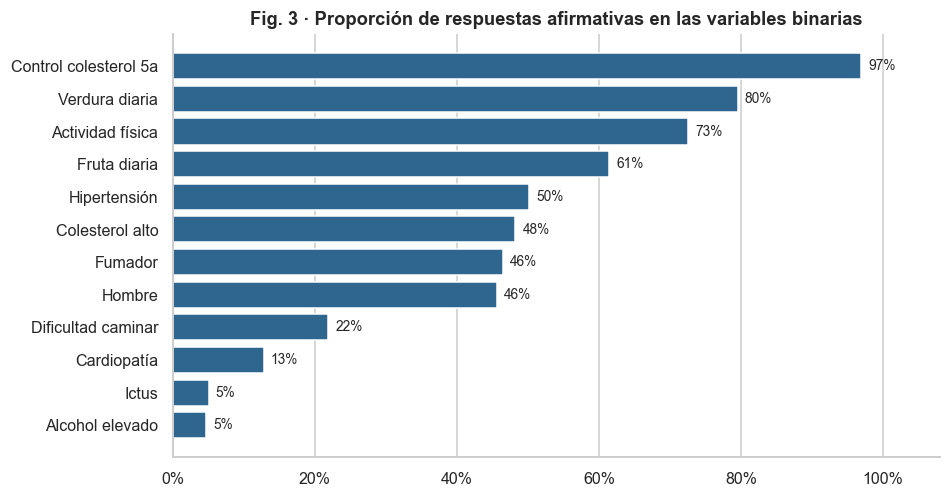

In [14]:
binarias = pp.COLS_BINARIAS
pct = datos[binarias].mean().sort_values()
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh([NOMBRES[c] for c in pct.index], pct, color=eu.AZUL)
for i, v in enumerate(pct):
    ax.text(v + 0.01, i, f"{v:.0%}", va="center", fontsize=9)
ax.set_xlim(0, 1.08)
eu.rejilla_x(ax)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("Fig. 3 · Proporción de respuestas afirmativas en las variables binarias")
eu.guardar_figura(fig, "fig03_binarias")
plt.show()

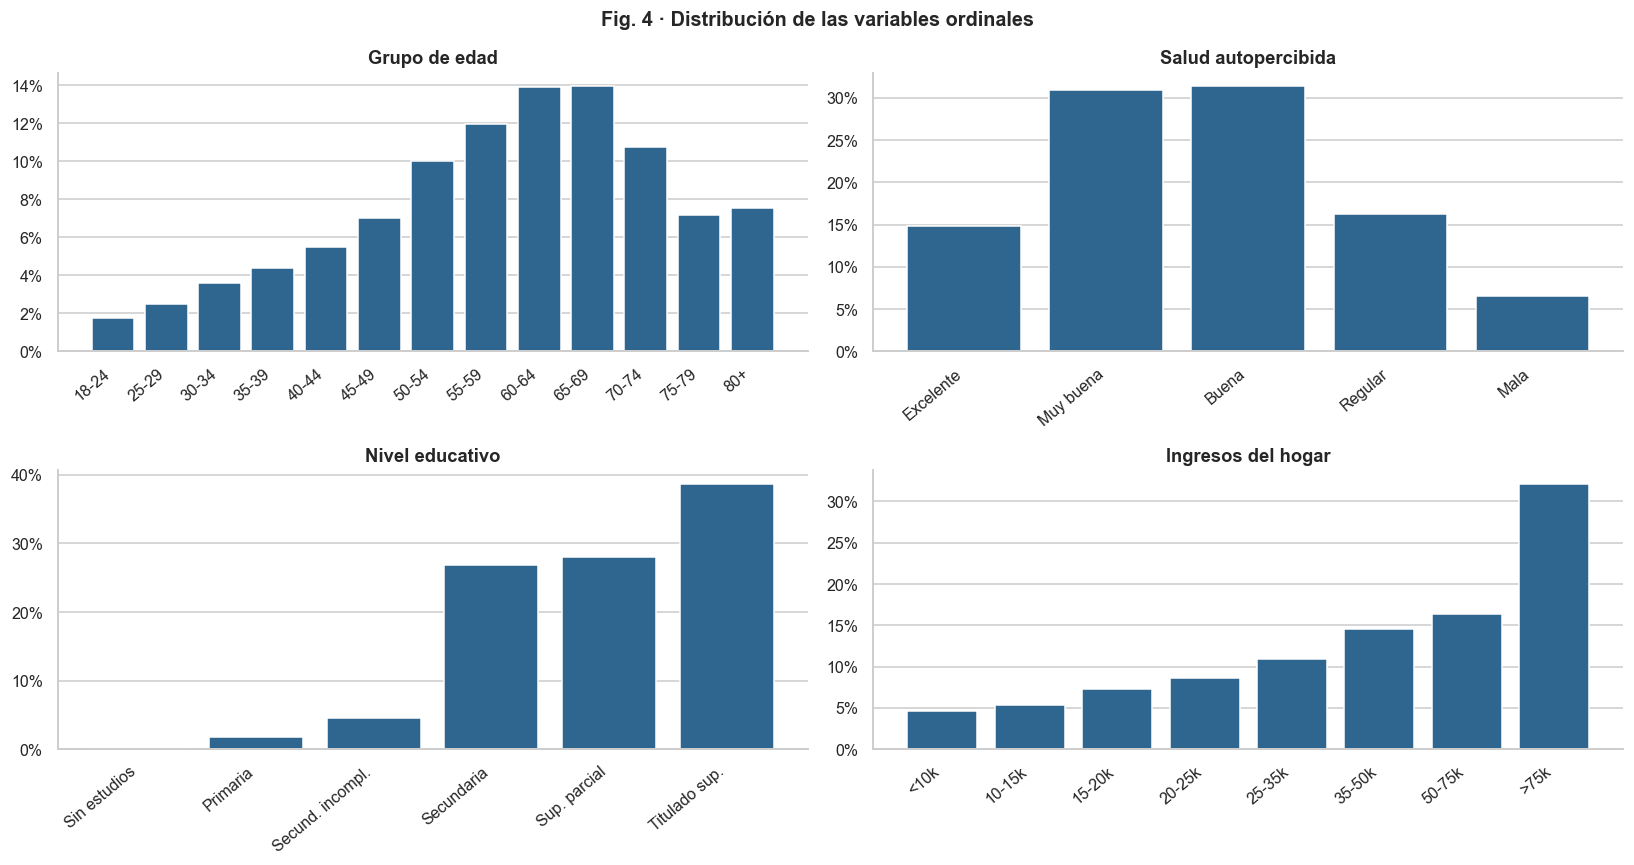

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(15, 8))
for ax, col in zip(axes.flat, pp.COLS_ORDINALES):
    conteo = datos[col].value_counts(normalize=True).sort_index()
    ax.bar([ETQ[col][int(i)] for i in conteo.index], conteo.values, color=eu.AZUL)
    ax.set_title(NOMBRES[col])
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.tick_params(axis="x", rotation=40)
    for lbl in ax.get_xticklabels():
        lbl.set_ha("right")
fig.suptitle("Fig. 4 · Distribución de las variables ordinales")
fig.tight_layout()
eu.guardar_figura(fig, "fig04_ordinales")
plt.show()

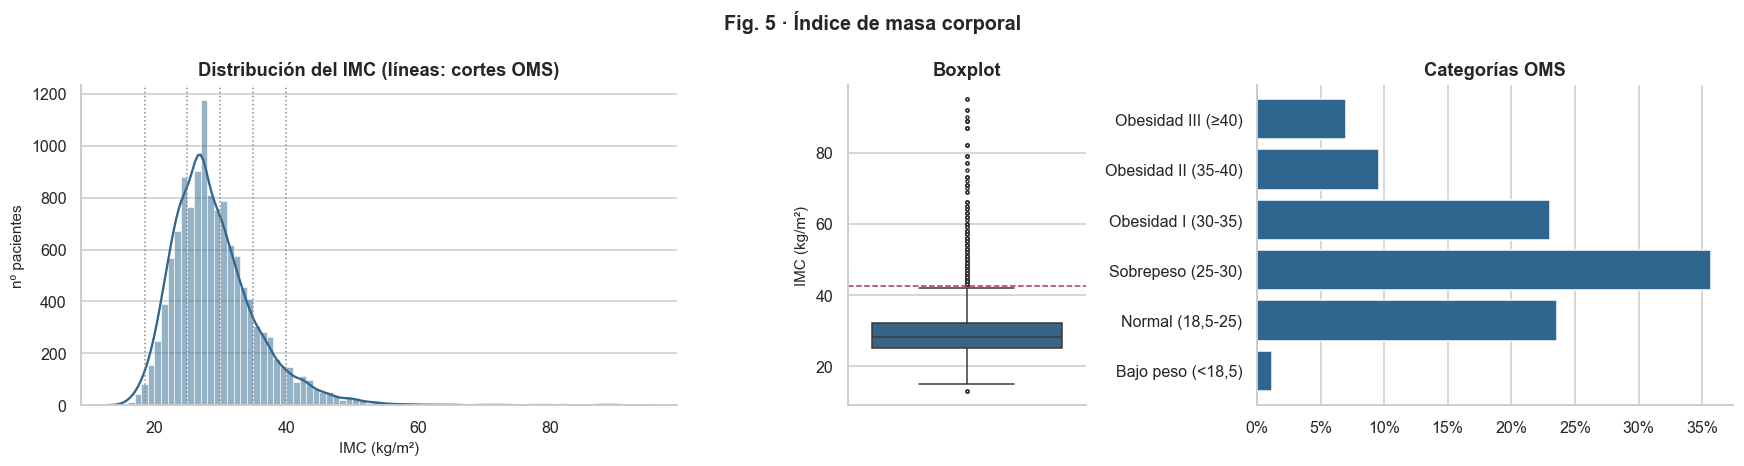

Asimetría: 2.04 · curtosis: 10.24
Outliers por IQR (> 42.5): 514 (4.2%) · IMC ≥ 60: 51
Sobrepeso u obesidad (IMC ≥ 25): 75.3%


In [16]:
imc = datos["imc"].dropna()
q1, q3 = imc.quantile([0.25, 0.75])
lim_sup = q3 + 1.5 * (q3 - q1)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.3), gridspec_kw={"width_ratios": [1.5, 0.6, 1.2]})
sns.histplot(imc, binwidth=1, kde=True, color=eu.AZUL, ax=axes[0])
for corte in [18.5, 25, 30, 35, 40]:
    axes[0].axvline(corte, color=eu.GRIS, ls=":", lw=1)
axes[0].set_title("Distribución del IMC (líneas: cortes OMS)")
axes[0].set_xlabel("IMC (kg/m²)")
axes[0].set_ylabel("nº pacientes")

sns.boxplot(y=imc, ax=axes[1], color=eu.AZUL, fliersize=2)
axes[1].axhline(lim_sup, color=eu.ROJO, ls="--", lw=1)
axes[1].set_title("Boxplot")
axes[1].set_ylabel("IMC (kg/m²)")

cat = datos["imc_categoria"].value_counts(normalize=True).sort_index()
axes[2].barh([pp.CATEGORIAS_IMC[int(i)] for i in cat.index], cat.values, color=eu.AZUL)
axes[2].xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
axes[2].set_title("Categorías OMS")
eu.rejilla_x(axes[2])
fig.suptitle("Fig. 5 · Índice de masa corporal")
fig.tight_layout()
eu.guardar_figura(fig, "fig05_imc")
plt.show()

print(f"Asimetría: {stats.skew(imc):.2f} · curtosis: {stats.kurtosis(imc):.2f}")
print(f"Outliers por IQR (> {lim_sup:.1f}): {(imc > lim_sup).sum()} ({(imc > lim_sup).mean():.1%}) · IMC ≥ 60: {(imc >= 60).sum()}")
print(f"Sobrepeso u obesidad (IMC ≥ 25): {(imc >= 25).mean():.1%}")

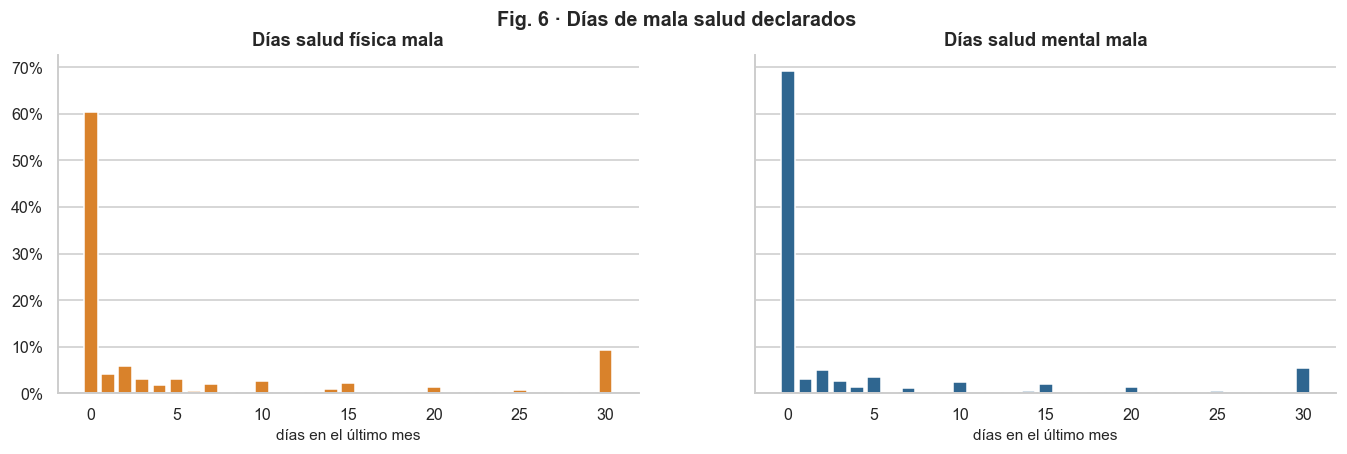

Correlación de Spearman entre ambos: 0.33


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4), sharey=True)
for ax, col, color in zip(axes, ["dias_salud_fisica_mala", "dias_salud_mental_mala"], [eu.NARANJA, eu.AZUL]):
    frec = datos[col].value_counts(normalize=True).sort_index()
    ax.bar(frec.index, frec.values, color=color)
    ax.set_title(NOMBRES[col])
    ax.set_xlabel("días en el último mes")
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
fig.suptitle("Fig. 6 · Días de mala salud declarados")
eu.guardar_figura(fig, "fig06_dias_mala_salud")
plt.show()
print(f"Correlación de Spearman entre ambos: {datos[['dias_salud_fisica_mala', 'dias_salud_mental_mala']].corr('spearman').iloc[0, 1]:.2f}")

**Hallazgos**
- **Prevalencias clínicas altas**, coherentes con una muestra enriquecida en diabéticos: ~50 % hipertensión, ~48 % colesterol alto, 13 % cardiopatía, 5 % ictus. Casi todos se han controlado el colesterol (97 %) → `chequeo_colesterol_5a` tiene **varianza muy baja** y probablemente aporte poco.
- `consumo_alcohol_alto` (5 %), `ictus` (5 %) y `chequeo_colesterol_5a` (3 % de "no") son variables **muy desbalanceadas**: poca información individual, a vigilar en modelos lineales.
- La edad se concentra en **55–74 años**; los ingresos y la educación están sesgados hacia los niveles altos. `nivel_educativo = sin estudios` tiene solo 7 casos (categoría casi vacía; al tratarla como ordinal no supone problema).
- **IMC**: mediana 28, asimetría positiva marcada y cola larga hasta 95; un **75 % tiene sobrepeso u obesidad**. Hay ~500 outliers por el criterio IQR, pero son **valores clínicamente reales** (obesidad III), muy informativos para la diabetes → **no se eliminan ni se recortan**; se usa la mediana para imputar (robusta a la cola) y se añade la categoría OMS como variable interpretable.
- Los dos recuentos de días tienen la misma forma: **mayoría de ceros y pico en 30**, con correlación moderada entre sí.

<a id="5"></a>
## 5. Variables objetivo

### 5.1 `diabetes` (clasificación)

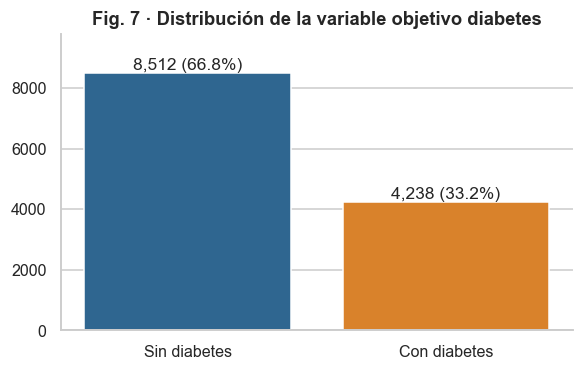

In [18]:
conteo = datos["diabetes"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar([eu.ETIQUETAS_DIABETES[i] for i in conteo.index], conteo.values, color=[eu.AZUL, eu.NARANJA])
for i, v in enumerate(conteo.values):
    ax.text(i, v + 100, f"{v:,} ({v / conteo.sum():.1%})", ha="center")
ax.set_ylim(0, conteo.max() * 1.15)
ax.set_title("Fig. 7 · Distribución de la variable objetivo diabetes")
eu.guardar_figura(fig, "fig07_target_diabetes")
plt.show()

**Hallazgos**
- Un **33,2 %** de los registros son diabéticos. Esta proporción es **artificial**: el consorcio ha remuestreado de forma estratificada para que ~1/3 sean casos. En la población real (encuestas tipo BRFSS) la prevalencia ronda el 10–15 %.
- Implicaciones:
  - El desbalance es **moderado** (1:2): no hacen falta técnicas agresivas de *resampling*; basta con estratificar las particiones y, en todo caso, usar `class_weight`.
  - Las **probabilidades** que devuelva el modelo **no son poblacionales**; si se quisieran usar como riesgo real habría que recalibrarlas a la prevalencia verdadera (corrección del *prior*). Es una limitación que se recogerá en el informe.
  - Como herramienta de **cribado**, el coste de un falso negativo (diabético no citado) es mayor que el de un falso positivo: se priorizarán métricas como **recall/sensibilidad, AUC-ROC y AUC-PR**, y el umbral se elegirá según el compromiso deseado, no fijado en 0,5.

### 5.2 `dias_salud_fisica_mala` (regresión)

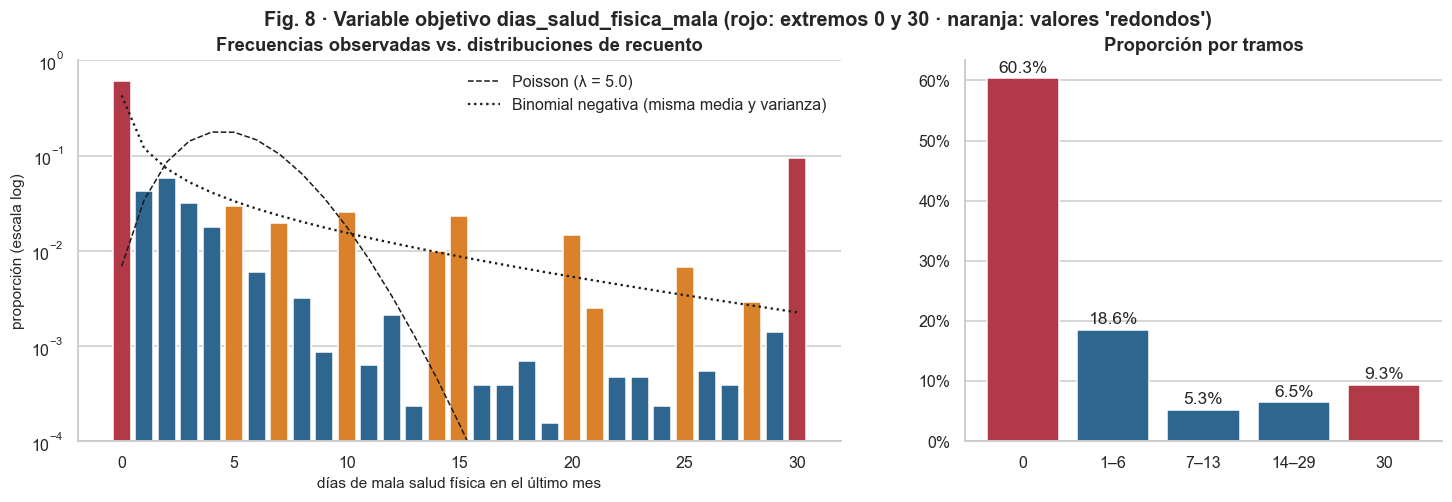

Media = 4.98 · mediana = 0 · varianza = 88.9 · índice de dispersión (var/media) = 17.9
P(y = 0) observada = 60.3% vs. Poisson = 0.7%
P(y = 30) = 9.3% · media entre los que declaran algún día = 12.6


In [19]:
y = datos["dias_salud_fisica_mala"]
media, var = y.mean(), y.var()
frec = y.value_counts(normalize=True).reindex(range(31), fill_value=0)

# Distribuciones de referencia con la misma media: Poisson y binomial negativa (método de momentos)
p_nb = media / var
r_nb = media * p_nb / (1 - p_nb)
poisson = stats.poisson.pmf(range(31), media)
binneg = stats.nbinom.pmf(range(31), r_nb, p_nb)

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5), gridspec_kw={"width_ratios": [1.6, 1]})
colores = [eu.ROJO if d in (0, 30) else (eu.NARANJA if d % 5 == 0 or d in (7, 14, 21, 28) else eu.AZUL) for d in range(31)]
axes[0].bar(range(31), frec.values, color=colores)
axes[0].plot(range(31), poisson, "k--", lw=1, label=f"Poisson (λ = {media:.1f})")
axes[0].plot(range(31), binneg, "k:", lw=1.5, label="Binomial negativa (misma media y varianza)")
axes[0].set_yscale("log")
axes[0].set_ylim(1e-4, 1)
axes[0].set_xlabel("días de mala salud física en el último mes")
axes[0].set_ylabel("proporción (escala log)")
axes[0].set_title("Frecuencias observadas vs. distribuciones de recuento")
axes[0].legend()

tramos = pd.cut(y, [-0.5, 0.5, 6.5, 13.5, 29.5, 30.5], labels=["0", "1–6", "7–13", "14–29", "30"]).value_counts(normalize=True).sort_index()
axes[1].bar(tramos.index.astype(str), tramos.values, color=[eu.ROJO, eu.AZUL, eu.AZUL, eu.AZUL, eu.ROJO])
for i, v in enumerate(tramos.values):
    axes[1].text(i, v + 0.01, f"{v:.1%}", ha="center")
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
axes[1].set_title("Proporción por tramos")
fig.suptitle("Fig. 8 · Variable objetivo dias_salud_fisica_mala (rojo: extremos 0 y 30 · naranja: valores 'redondos')")
eu.guardar_figura(fig, "fig08_target_regresion")
plt.show()

print(f"Media = {media:.2f} · mediana = {y.median():.0f} · varianza = {var:.1f} · índice de dispersión (var/media) = {var / media:.1f}")
print(f"P(y = 0) observada = {(y == 0).mean():.1%} vs. Poisson = {poisson[0]:.1%}")
print(f"P(y = 30) = {(y == 30).mean():.1%} · media entre los que declaran algún día = {y[y > 0].mean():.1f}")

**Hallazgos**
- La variable es un **recuento acotado [0, 30], cero-inflado y bimodal**: un **60 % de ceros** (una Poisson con la misma media predeciría < 1 %) y un **9 % en el máximo**, 30 días (personas con enfermedad crónica que se encuentran mal "todo el mes").
- **Sobredispersión extrema**: la varianza (88,9) es ~18 veces la media (5,0). Ni Poisson ni binomial negativa reproducen el pico en 30.
- **Heaping** (redondeo de autorreporte): los valores 5, 10, 15, 20, 25 y 30 (y 7, 14, 21, "una/dos semanas") son mucho más frecuentes que sus vecinos. El encuestado responde de forma aproximada → hay un **ruido irreducible** que limita el error mínimo alcanzable.
- Implicaciones para el modelado (próximas fases):
  - Una regresión por mínimos cuadrados predecirá valores "intermedios" (≈ 5) que casi nadie declara. Alternativas a probar: **modelo de dos partes / *hurdle*** (¿algún día? × ¿cuántos?), **regresión Tweedie/Poisson** con GBM, o enfoques de clasificación ordinal por tramos.
  - La métrica principal debería ser el **MAE** (robusto y fácil de explicar: "nos equivocamos en X días"), complementada con RMSE. La media marginal deja un MAE de referencia que cualquier modelo debe batir.
  - Las particiones se **estratifican por tramos** (0 / 1–29 / 30) para conservar la forma de la distribución en train y test.

<a id="6"></a>
## 6. Relación de los predictores con `diabetes`

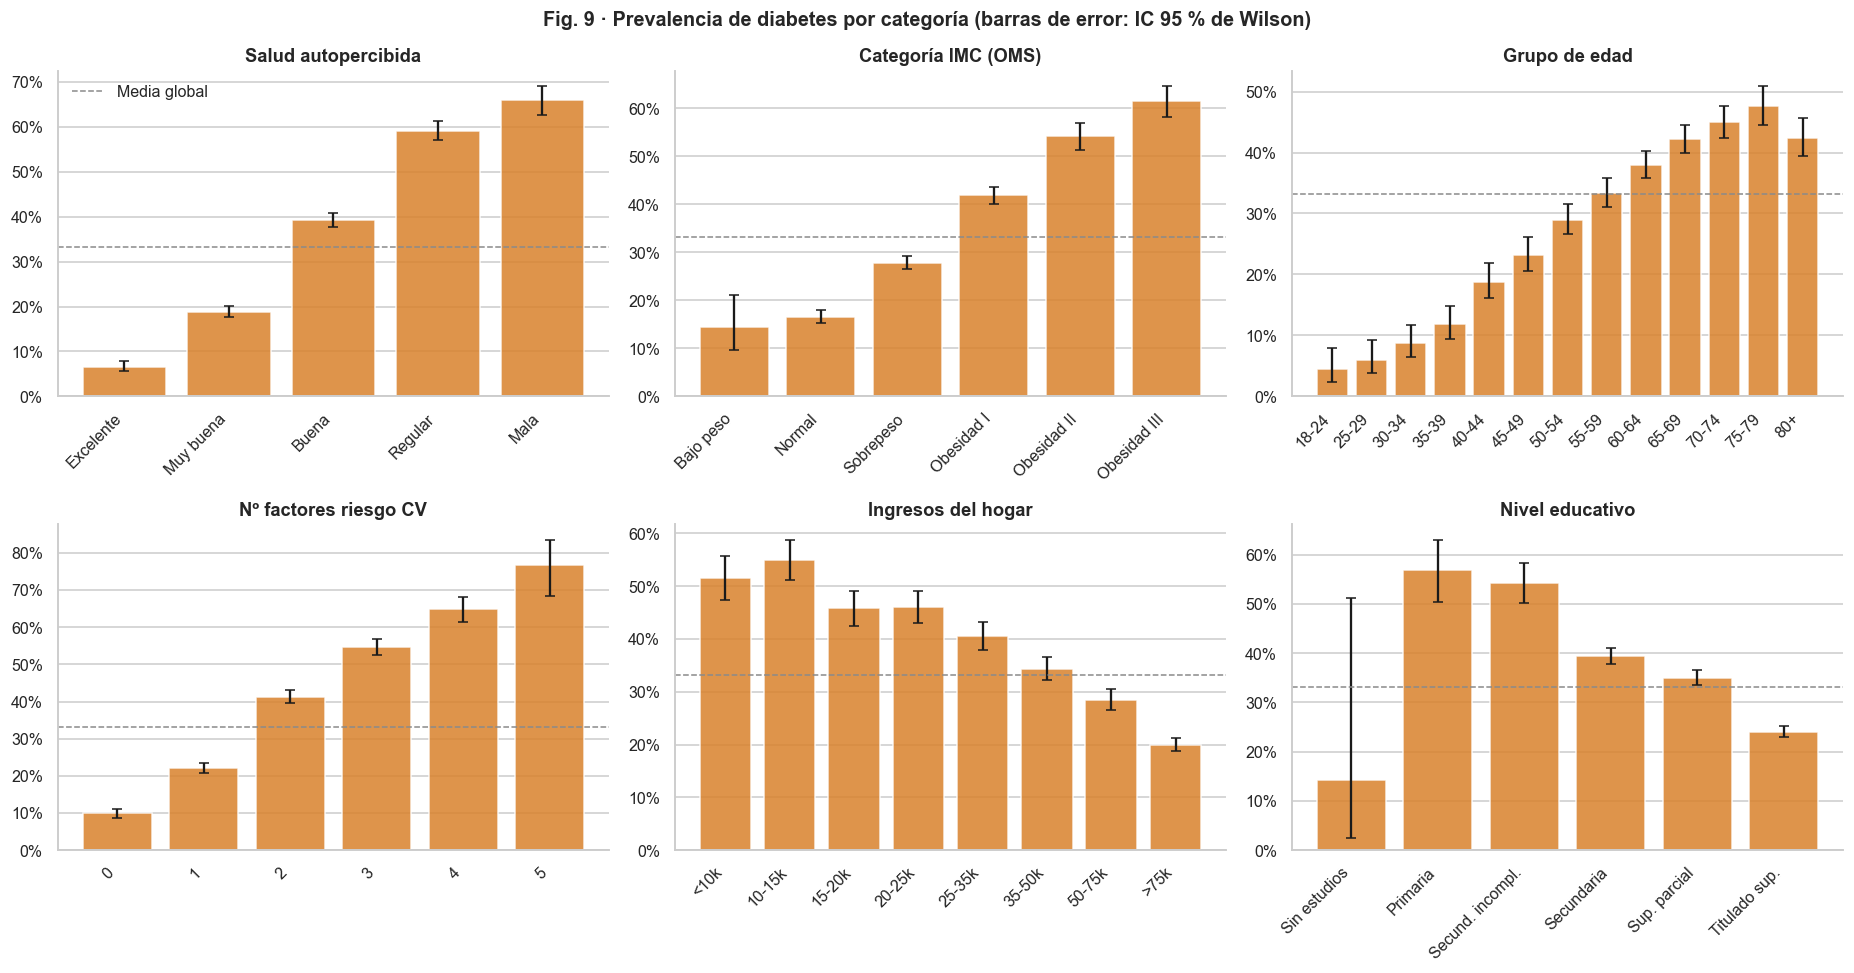

In [20]:
cols_graf = ["salud_general", "imc_categoria", "grupo_edad", "n_factores_riesgo_cv", "nivel_ingresos", "nivel_educativo"]
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for ax, col in zip(axes.flat, cols_graf):
    etq = {k: v.split(" (")[0] for k, v in ETQ[col].items()} if col in ETQ else {i: int(i) for i in range(10)}
    eu.barras_prevalencia(datos, col, "diabetes", ax, etiquetas=etq, titulo=NOMBRES[col])
axes[0, 0].legend(loc="upper left")
fig.suptitle("Fig. 9 · Prevalencia de diabetes por categoría (barras de error: IC 95 % de Wilson)")
fig.tight_layout()
eu.guardar_figura(fig, "fig09_prevalencia_diabetes_ordinales")
plt.show()

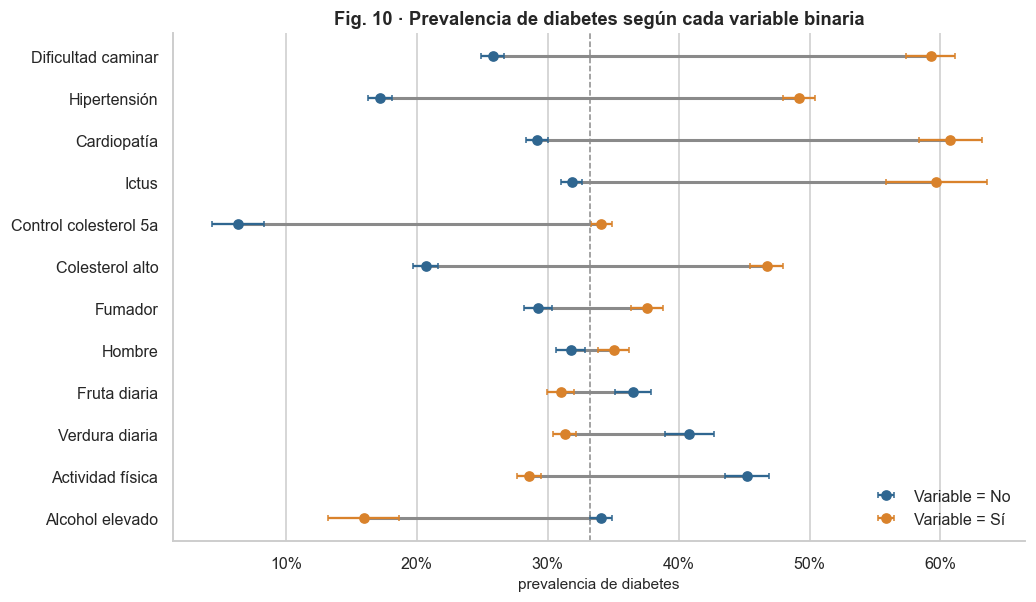

In [21]:
filas = []
for col in binarias:
    t = eu.tabla_prevalencia(datos, col, "diabetes")
    filas.append({"variable": NOMBRES[col], "No": t.loc[0, "prevalencia"], "Sí": t.loc[1, "prevalencia"],
                  "err_no": t.loc[0, "prevalencia"] - t.loc[0, "ic_inf"], "err_si": t.loc[1, "prevalencia"] - t.loc[1, "ic_inf"]})
prev_bin = pd.DataFrame(filas).assign(dif=lambda d: d["Sí"] - d["No"]).sort_values("dif")

fig, ax = plt.subplots(figsize=(10, 6))
pos = np.arange(len(prev_bin))
ax.hlines(pos, prev_bin["No"], prev_bin["Sí"], color=eu.GRIS, lw=2)
ax.errorbar(prev_bin["No"], pos, xerr=prev_bin["err_no"], fmt="o", color=eu.AZUL, label="Variable = No", capsize=2)
ax.errorbar(prev_bin["Sí"], pos, xerr=prev_bin["err_si"], fmt="o", color=eu.NARANJA, label="Variable = Sí", capsize=2)
ax.axvline(datos["diabetes"].mean(), color=eu.GRIS, ls="--", lw=1)
ax.set_yticks(pos, prev_bin["variable"])
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlabel("prevalencia de diabetes")
ax.legend(loc="lower right")
eu.rejilla_x(ax)
ax.set_title("Fig. 10 · Prevalencia de diabetes según cada variable binaria")
eu.guardar_figura(fig, "fig10_prevalencia_diabetes_binarias")
plt.show()

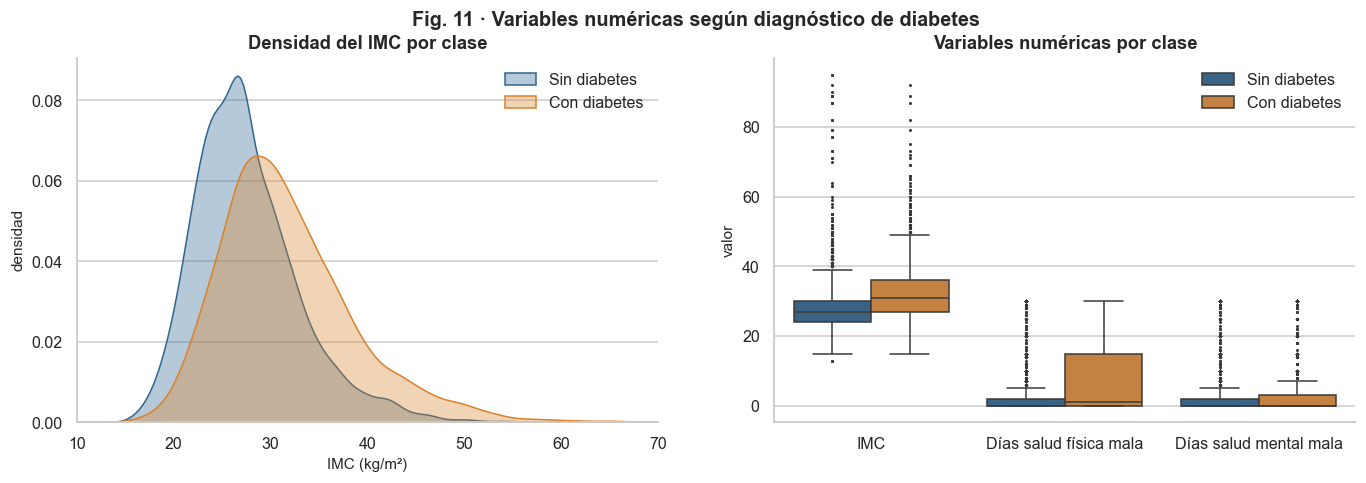

imc                      mediana con/sin diabetes:  31.0 /  27.0 · p = 2.2e-249 · δ de Cliff = 0.37
dias_salud_fisica_mala   mediana con/sin diabetes:   1.0 /   0.0 · p = 8.1e-137 · δ de Cliff = 0.24
dias_salud_mental_mala   mediana con/sin diabetes:   0.0 /   0.0 · p = 7.9e-13 · δ de Cliff = 0.06


In [22]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.3))
for clase in (0, 1):
    sns.kdeplot(datos.loc[datos.diabetes == clase, "imc"], ax=axes[0], fill=True, alpha=0.35, color=eu.PALETA_DIABETES[clase],
                label=eu.ETIQUETAS_DIABETES[clase], clip=(10, 70))
axes[0].set_xlim(10, 70)
axes[0].set_xlabel("IMC (kg/m²)")
axes[0].set_ylabel("densidad")
axes[0].set_title("Densidad del IMC por clase")
axes[0].legend()

melt = datos.melt(id_vars="diabetes", value_vars=["imc", "dias_salud_fisica_mala", "dias_salud_mental_mala"], var_name="variable")
melt["variable"] = melt["variable"].map(NOMBRES)
melt["diabetes"] = melt["diabetes"].map(eu.ETIQUETAS_DIABETES)
sns.boxplot(data=melt, x="variable", y="value", hue="diabetes", ax=axes[1], palette=[eu.AZUL, eu.NARANJA], fliersize=1)
axes[1].set_xlabel("")
axes[1].set_ylabel("valor")
axes[1].set_title("Variables numéricas por clase")
axes[1].legend(title="")
fig.suptitle("Fig. 11 · Variables numéricas según diagnóstico de diabetes")
eu.guardar_figura(fig, "fig11_numericas_por_diabetes")
plt.show()

for col in ["imc", "dias_salud_fisica_mala", "dias_salud_mental_mala"]:
    r = eu.test_mann_whitney(datos.loc[datos.diabetes == 1, col], datos.loc[datos.diabetes == 0, col])
    print(f"{col:<24} mediana con/sin diabetes: {datos.loc[datos.diabetes == 1, col].median():5.1f} / {datos.loc[datos.diabetes == 0, col].median():5.1f}"
          f" · p = {r['p_valor']:.1e} · δ de Cliff = {r['delta_cliff']:.2f}")

**Ranking de asociación con `diabetes`.** Usamos dos medidas complementarias: un tamaño del efecto clásico (V de Cramér para categóricas/ordinales, |δ de Cliff| para numéricas) y la **información mutua**, que capta dependencias no lineales y es comparable entre tipos de variable.

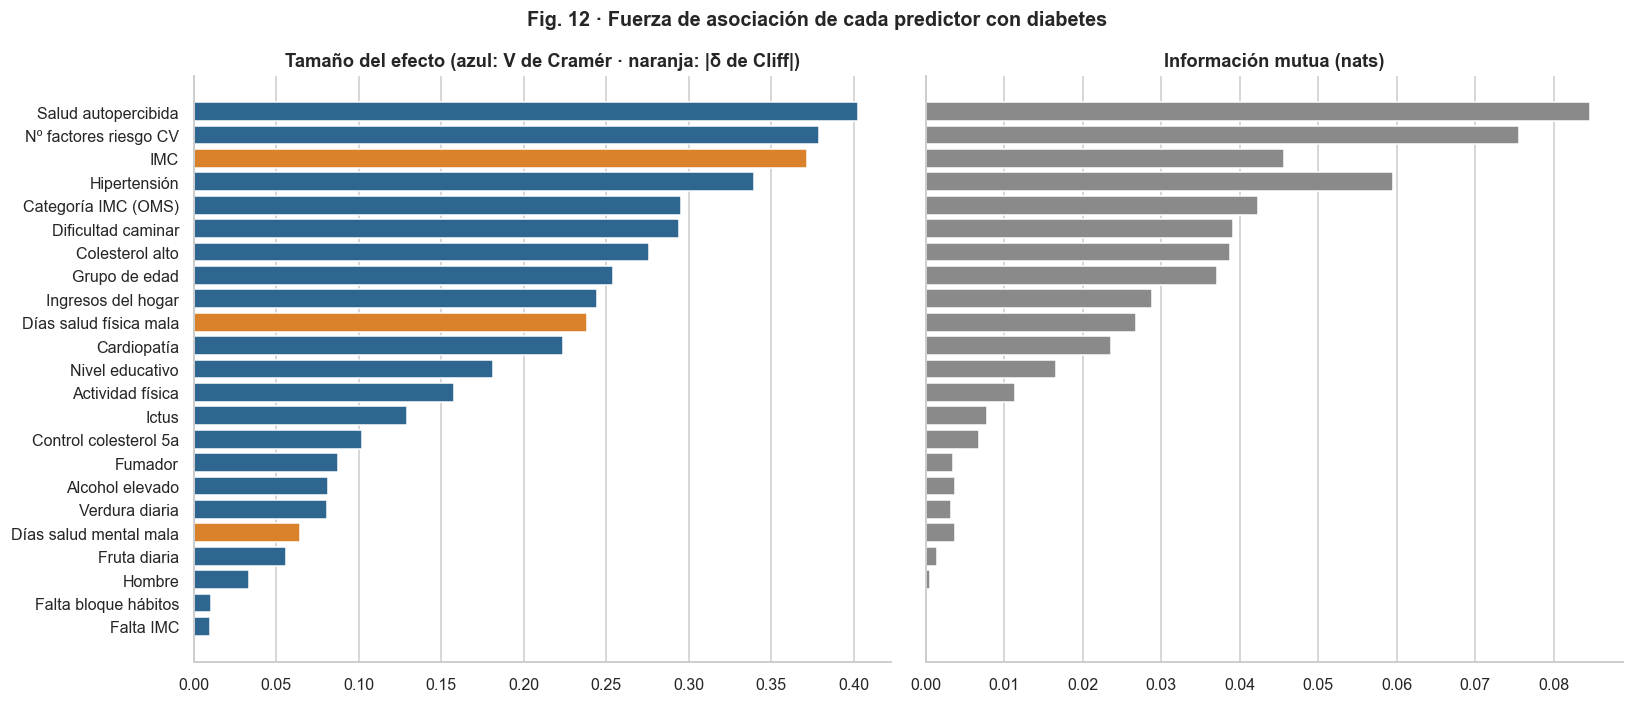

,medida,efecto,p_valor,info_mutua
variable,,,,
salud_general,V de Cramér,0.403,0.0e+00,0.0847
n_factores_riesgo_cv,V de Cramér,0.379,0.0e+00,0.0756
imc,|δ de Cliff|,0.372,2.2e-249,0.0456
presion_alta,V de Cramér,0.340,0.0e+00,0.0596
imc_categoria,V de Cramér,0.295,6.4e-232,0.0423
dificultad_caminar,V de Cramér,0.294,2.3e-234,0.0392
colesterol_alto,V de Cramér,0.276,2.3e-213,0.0387
grupo_edad,V de Cramér,0.254,7.7e-171,0.0371
nivel_ingresos,V de Cramér,0.244,4.3e-153,0.0288


In [23]:
predictores = [c for c in datos.columns if c not in ("diabetes",)]
numericas = ["imc", "dias_salud_mental_mala", "dias_salud_fisica_mala"]
filas = []
for col in predictores:
    if col in numericas:
        r = eu.test_mann_whitney(datos.loc[datos.diabetes == 1, col], datos.loc[datos.diabetes == 0, col])
        filas.append({"variable": col, "medida": "|δ de Cliff|", "efecto": abs(r["delta_cliff"]), "p_valor": r["p_valor"]})
    else:
        r = eu.test_chi2(datos[col], datos["diabetes"])
        filas.append({"variable": col, "medida": "V de Cramér", "efecto": r["v_cramer"], "p_valor": r["p_valor"]})
asoc_diab = pd.DataFrame(filas).set_index("variable")

X_mi = datos[predictores].fillna(datos[predictores].median())
discretas = [c not in numericas for c in predictores]
asoc_diab["info_mutua"] = mutual_info_classif(X_mi, datos["diabetes"], discrete_features=discretas, random_state=0)
asoc_diab = asoc_diab.sort_values("efecto", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(15, 6.5), sharey=True)
etiquetas = [NOMBRES.get(c, c) for c in asoc_diab.index]
axes[0].barh(etiquetas, asoc_diab["efecto"], color=[eu.NARANJA if m.startswith("|") else eu.AZUL for m in asoc_diab["medida"]])
axes[0].invert_yaxis()
axes[0].set_title("Tamaño del efecto (azul: V de Cramér · naranja: |δ de Cliff|)")
axes[1].barh(etiquetas, asoc_diab["info_mutua"], color=eu.GRIS)
axes[1].set_title("Información mutua (nats)")
for ax in axes:
    eu.rejilla_x(ax)
fig.suptitle("Fig. 12 · Fuerza de asociación de cada predictor con diabetes")
fig.tight_layout()
eu.guardar_figura(fig, "fig12_ranking_asociacion_diabetes")
plt.show()
asoc_diab.style.format({"efecto": "{:.3f}", "p_valor": "{:.1e}", "info_mutua": "{:.4f}"}).bar(subset=["efecto", "info_mutua"], color="#9DB9D3")

**Hallazgos**
- **Gradientes monótonos y fuertes** en todas las ordinales clave: la prevalencia de diabetes pasa del **7 %** con salud "excelente" al **66 %** con salud "mala"; del **17 %** con IMC normal al **61 %** en obesidad III; del **4 %** en 18–24 años al **48 %** en 75–79; y del **52 %** con ingresos < 10k al **20 %** con > 75k. Su monotonía **justifica codificarlas como ordinales** (enteros) en lugar de *one-hot*.
- La variable derivada **`n_factores_riesgo_cv`** es la segunda más asociada (V = 0,38; del 10 % sin factores al 77 % con los 5): resume bien el riesgo cardiometabólico y **valida su creación**.
- Entre las binarias destacan **hipertensión** (prevalencia del 49 % frente al 17 %), **colesterol alto** (47 % vs 21 %), **dificultad para caminar** (59 % vs 26 %), **cardiopatía** (61 % vs 29 %) e **ictus** (60 % vs 32 %). Los hábitos (fruta, verdura, tabaco) tienen efectos **pequeños**; la inactividad física eleva la prevalencia del 29 % al 45 %.
- Dos asociaciones "contraintuitivas" que conviene explicar y **no interpretar causalmente**: el consumo elevado de alcohol se asocia con *menos* diabetes (16 % vs 34 %; probable causalidad inversa: los enfermos reducen el consumo) y quien no se ha controlado el colesterol tiene muy poca diabetes (6 %), porque los diabéticos están en seguimiento médico.
- La prevalencia cae en el grupo **80+** respecto a 75–79, compatible con un **sesgo de supervivencia**. En educación, la categoría "sin estudios" (n = 7) tiene un IC enorme y no es interpretable.
- El **IMC** separa bien las clases (δ de Cliff = 0,37, efecto mediano; ~4 puntos de diferencia en la mediana). `sexo` y los indicadores de nulos apenas aportan (V < 0,04).
- Ningún predictor por sí solo separa las clases (máx. V ≈ 0,40): el problema requiere **combinar** variables, lo que anticipa un rendimiento razonable pero no perfecto. No se observan variables "demasiado buenas" que sugieran **fuga de información**.

<a id="7"></a>
## 7. Relación de los predictores con `dias_salud_fisica_mala`

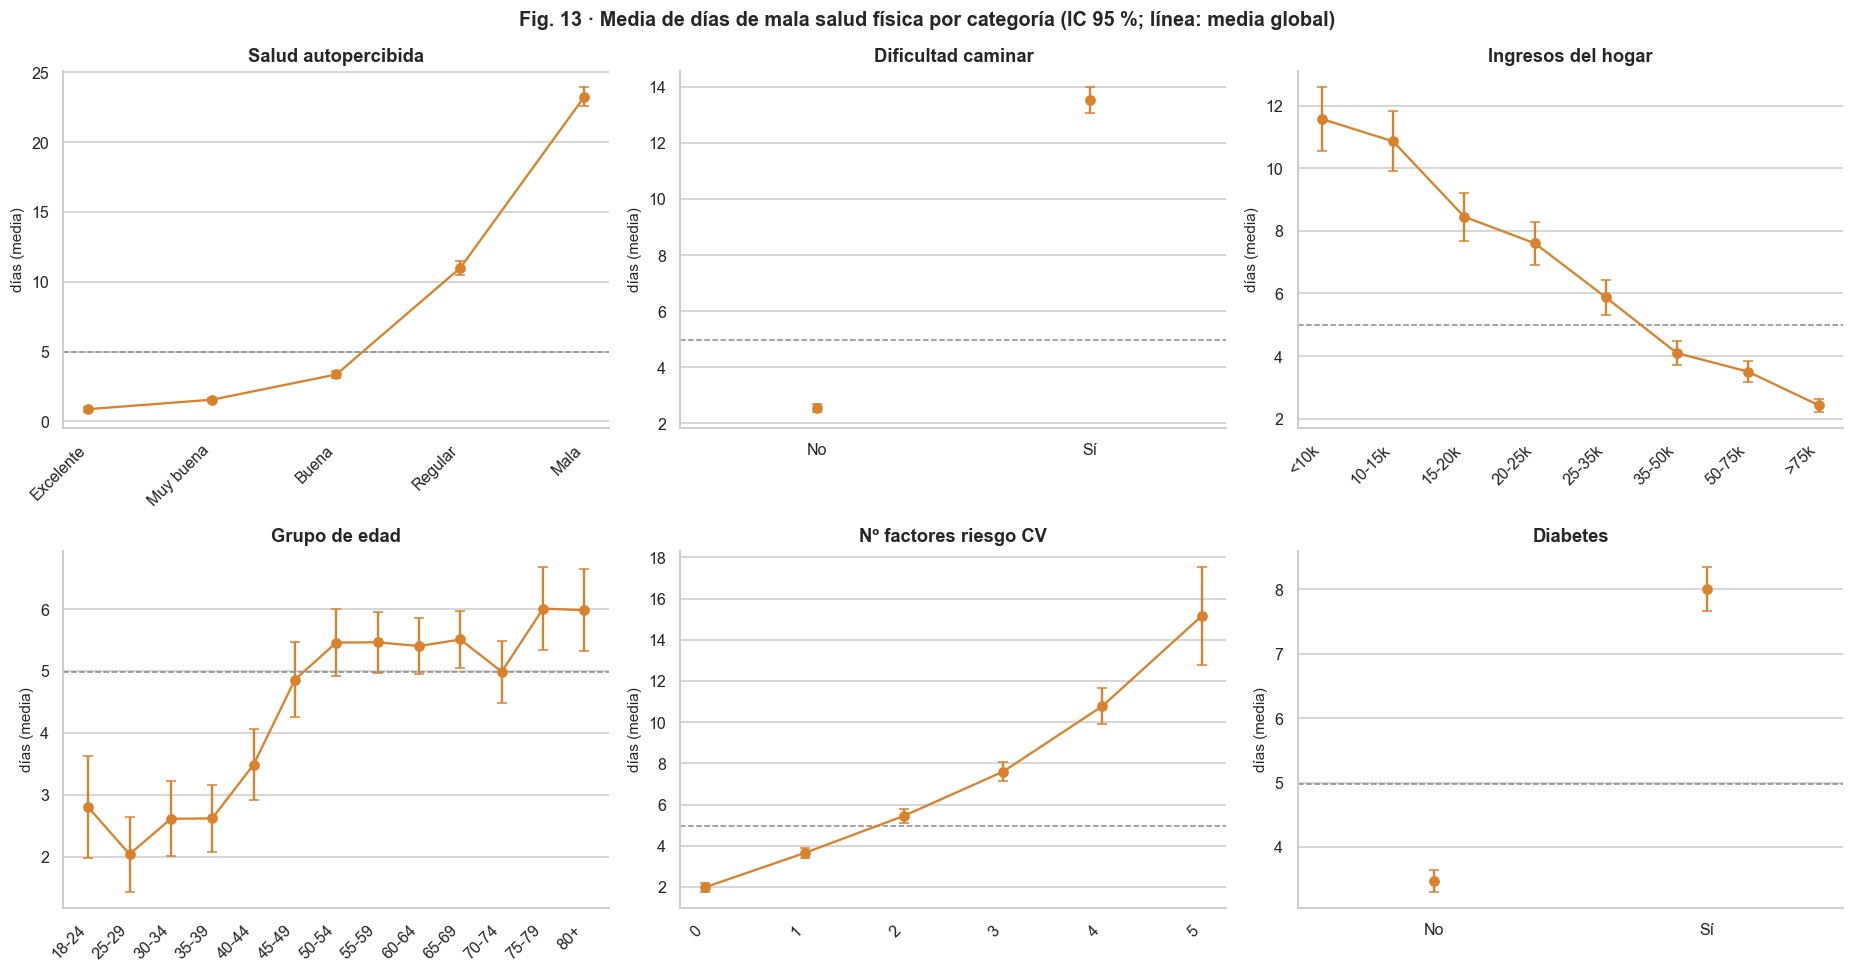

In [24]:
cols_graf = ["salud_general", "dificultad_caminar", "nivel_ingresos", "grupo_edad", "n_factores_riesgo_cv", "diabetes"]
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for ax, col in zip(axes.flat, cols_graf):
    etq = ETQ.get(col, {0: "No", 1: "Sí"} if datos[col].nunique() == 2 else None)
    eu.puntos_media_ic(datos, col, "dias_salud_fisica_mala", ax, etiquetas=etq, titulo=NOMBRES[col], color=eu.NARANJA)
    ax.set_ylabel("días (media)")
fig.suptitle("Fig. 13 · Media de días de mala salud física por categoría (IC 95 %; línea: media global)")
fig.tight_layout()
eu.guardar_figura(fig, "fig13_dias_por_categoria")
plt.show()

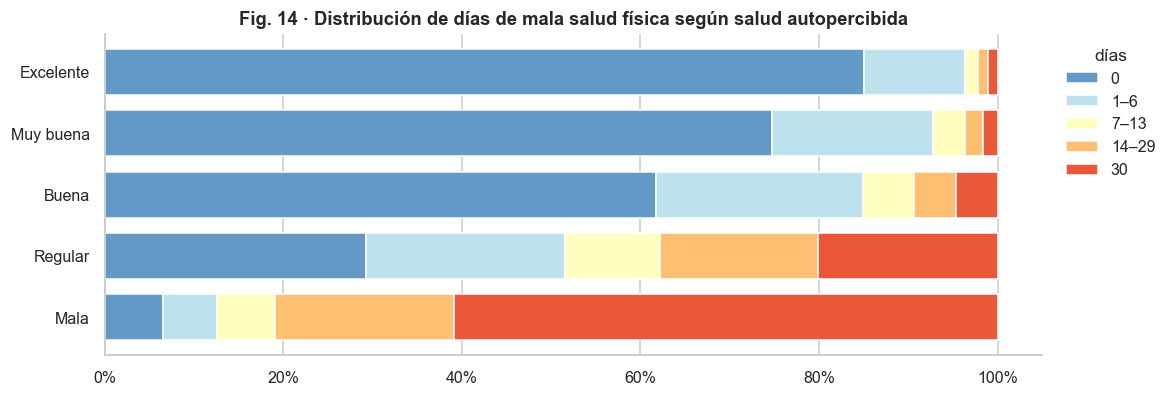

In [25]:
tramos_y = pd.cut(datos["dias_salud_fisica_mala"], [-0.5, 0.5, 6.5, 13.5, 29.5, 30.5], labels=["0", "1–6", "7–13", "14–29", "30"])
comp = pd.crosstab(datos["salud_general"].map(ETQ["salud_general"]), tramos_y, normalize="index").loc[list(ETQ["salud_general"].values())]

fig, ax = plt.subplots(figsize=(11, 3.8))
comp.plot(kind="barh", stacked=True, ax=ax, color=sns.color_palette("RdYlBu_r", 5), width=0.75)
ax.invert_yaxis()
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.legend(title="días", bbox_to_anchor=(1.01, 1), loc="upper left")
ax.set_ylabel("")
eu.rejilla_x(ax)
ax.set_title("Fig. 14 · Distribución de días de mala salud física según salud autopercibida")
eu.guardar_figura(fig, "fig14_dias_vs_salud_general")
plt.show()

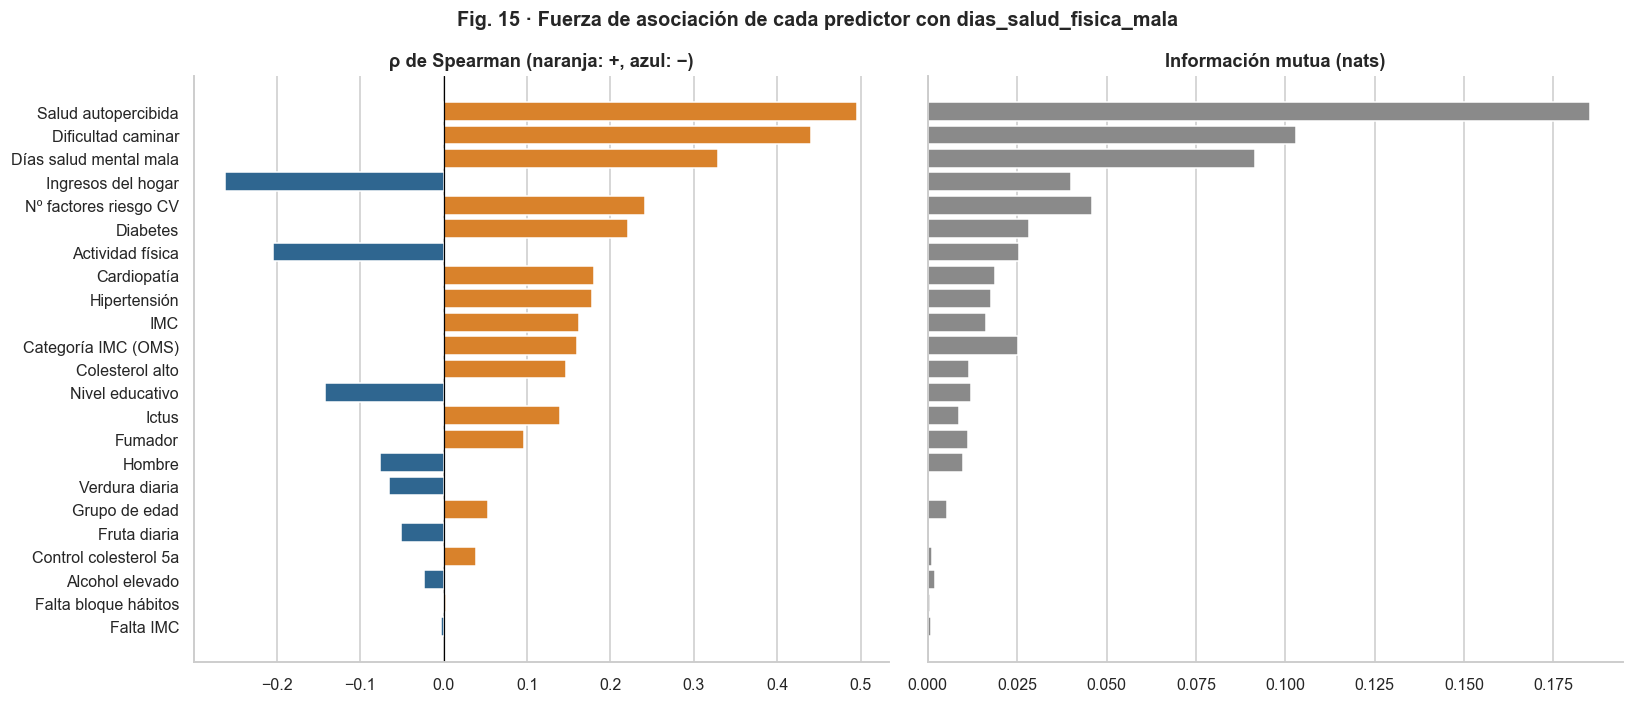

,rho_spearman,p_valor,epsilon2_kruskal,info_mutua
variable,,,,
salud_general,+0.496,0.0e+00,0.307,0.1853
dificultad_caminar,+0.440,0.0e+00,0.194,0.1029
dias_salud_mental_mala,+0.329,2.5e-310,—,0.0914
nivel_ingresos,-0.262,1.0e-188,0.075,0.0401
n_factores_riesgo_cv,+0.242,7.6e-169,0.063,0.0459
diabetes,+0.220,3.5e-140,0.049,0.0283
actividad_fisica,-0.204,1.3e-116,0.042,0.0255
enfermedad_cardiaca,+0.180,1.9e-93,0.032,0.0187
presion_alta,+0.178,1.1e-91,0.032,0.0177


In [26]:
predictores_r = [c for c in datos.columns if c != "dias_salud_fisica_mala"]
filas = []
for col in predictores_r:
    sub = datos[[col, "dias_salud_fisica_mala"]].dropna()
    rho, p = stats.spearmanr(sub[col], sub["dias_salud_fisica_mala"])
    fila = {"variable": col, "rho_spearman": rho, "p_valor": p}
    if col not in ("imc", "dias_salud_mental_mala"):
        fila["epsilon2_kruskal"] = eu.test_kruskal(datos, col, "dias_salud_fisica_mala")["epsilon2"]
    filas.append(fila)
asoc_regr = pd.DataFrame(filas).set_index("variable")
X_mi = datos[predictores_r].fillna(datos[predictores_r].median())
discretas = [c not in ("imc", "dias_salud_mental_mala") for c in predictores_r]
asoc_regr["info_mutua"] = mutual_info_regression(X_mi, datos["dias_salud_fisica_mala"], discrete_features=discretas, random_state=0)
asoc_regr = asoc_regr.sort_values("rho_spearman", key=abs, ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(15, 6.5), sharey=True)
etiquetas = [NOMBRES.get(c, c) for c in asoc_regr.index]
axes[0].barh(etiquetas, asoc_regr["rho_spearman"], color=[eu.NARANJA if v > 0 else eu.AZUL for v in asoc_regr["rho_spearman"]])
axes[0].invert_yaxis()
axes[0].axvline(0, color="black", lw=0.8)
axes[0].set_title("ρ de Spearman (naranja: +, azul: −)")
axes[1].barh(etiquetas, asoc_regr["info_mutua"], color=eu.GRIS)
axes[1].set_title("Información mutua (nats)")
for ax in axes:
    eu.rejilla_x(ax)
fig.suptitle("Fig. 15 · Fuerza de asociación de cada predictor con dias_salud_fisica_mala")
fig.tight_layout()
eu.guardar_figura(fig, "fig15_ranking_asociacion_regresion")
plt.show()
asoc_regr.style.format({"rho_spearman": "{:+.3f}", "p_valor": "{:.1e}", "epsilon2_kruskal": "{:.3f}", "info_mutua": "{:.4f}"}, na_rep="—")

**Hallazgos**
- La **salud autopercibida** es, con diferencia, el mejor predictor (ρ = 0,50; ε² = 0,31, efecto grande): de **0,9 días** de media en "excelente" a **23,3** en "mala". Con salud "mala", más de la mitad declara 30 días. Ambas variables miden en parte **el mismo constructo** (cómo se encuentra el paciente), así que su relación es esperable; no es una fuga porque `salud_general` se recoge en la misma encuesta y estará disponible en la predicción.
- Le siguen **`dificultad_caminar`** (ρ = 0,44; 13,5 días de media con dificultad frente a 2,5 sin ella), **días de mala salud mental** (ρ = 0,33), **nivel de ingresos** (ρ = −0,26, gradiente socioeconómico) y **actividad física** (ρ = −0,20).
- La carga cardiometabólica (`n_factores_riesgo_cv`, cardiopatía, hipertensión, **diabetes** con ρ = 0,22) tiene un efecto **moderado**.
- La **edad** tiene una correlación global muy baja (ρ = 0,05) pero su relación **no es lineal**: hay un escalón entre los 40 y los 50 años (de ~2,5 a ~5,5 días) y después una meseta. Un modelo lineal la infravaloraría; los árboles o una codificación por tramos la capturan mejor. En conjunto, los días de mala salud dependen más del estado funcional y socioeconómico que de la edad.
- Fruta, verdura, alcohol y los indicadores de nulos son prácticamente irrelevantes (información mutua ≈ 0) → candidatas a eliminarse en la selección de variables de esta línea.

<a id="8"></a>
## 8. Análisis multivariante

### 8.1 Correlaciones entre predictores

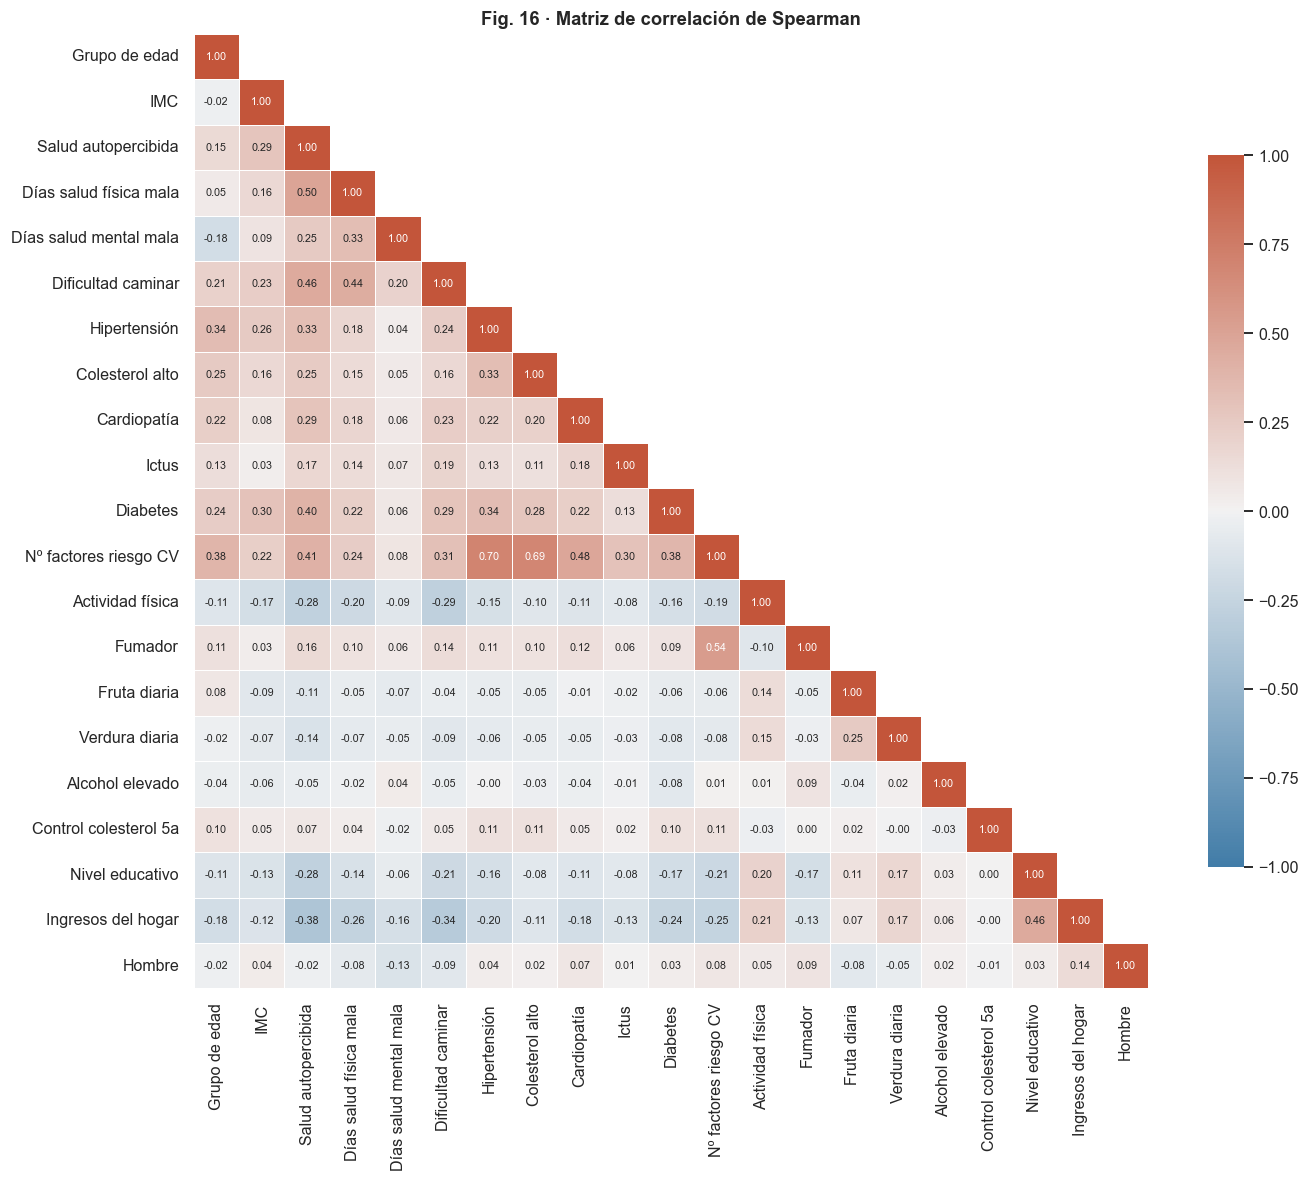

ρ
Hipertensión           Nº factores riesgo CV   0.700
Colesterol alto        Nº factores riesgo CV   0.687
Nº factores riesgo CV  Fumador                 0.544
Salud autopercibida    Días salud física mala  0.496
Cardiopatía            Nº factores riesgo CV   0.477
Nivel educativo        Ingresos del hogar      0.458
Salud autopercibida    Dificultad caminar      0.456
Días salud física mala Dificultad caminar      0.440
Salud autopercibida    Nº factores riesgo CV   0.411
                       Diabetes                0.401
Grupo de edad          Nº factores riesgo CV   0.384
Salud autopercibida    Ingresos del hogar     -0.382

In [27]:
orden_vars = ["grupo_edad", "imc", "salud_general", "dias_salud_fisica_mala", "dias_salud_mental_mala", "dificultad_caminar",
              "presion_alta", "colesterol_alto", "enfermedad_cardiaca", "ictus", "diabetes", "n_factores_riesgo_cv",
              "actividad_fisica", "fumador", "consume_fruta", "consume_verdura", "consumo_alcohol_alto",
              "chequeo_colesterol_5a", "nivel_educativo", "nivel_ingresos", "es_hombre"]
spearman = datos[orden_vars].corr(method="spearman").rename(index=NOMBRES, columns=NOMBRES)

fig, ax = plt.subplots(figsize=(14, 12))
eu.heatmap_correlacion(spearman, ax, "Fig. 16 · Matriz de correlación de Spearman")
eu.guardar_figura(fig, "fig16_spearman")
plt.show()

pares = spearman.where(np.triu(np.ones(spearman.shape, dtype=bool), k=1)).stack().sort_values(key=abs, ascending=False)
pares.head(12).to_frame("ρ")

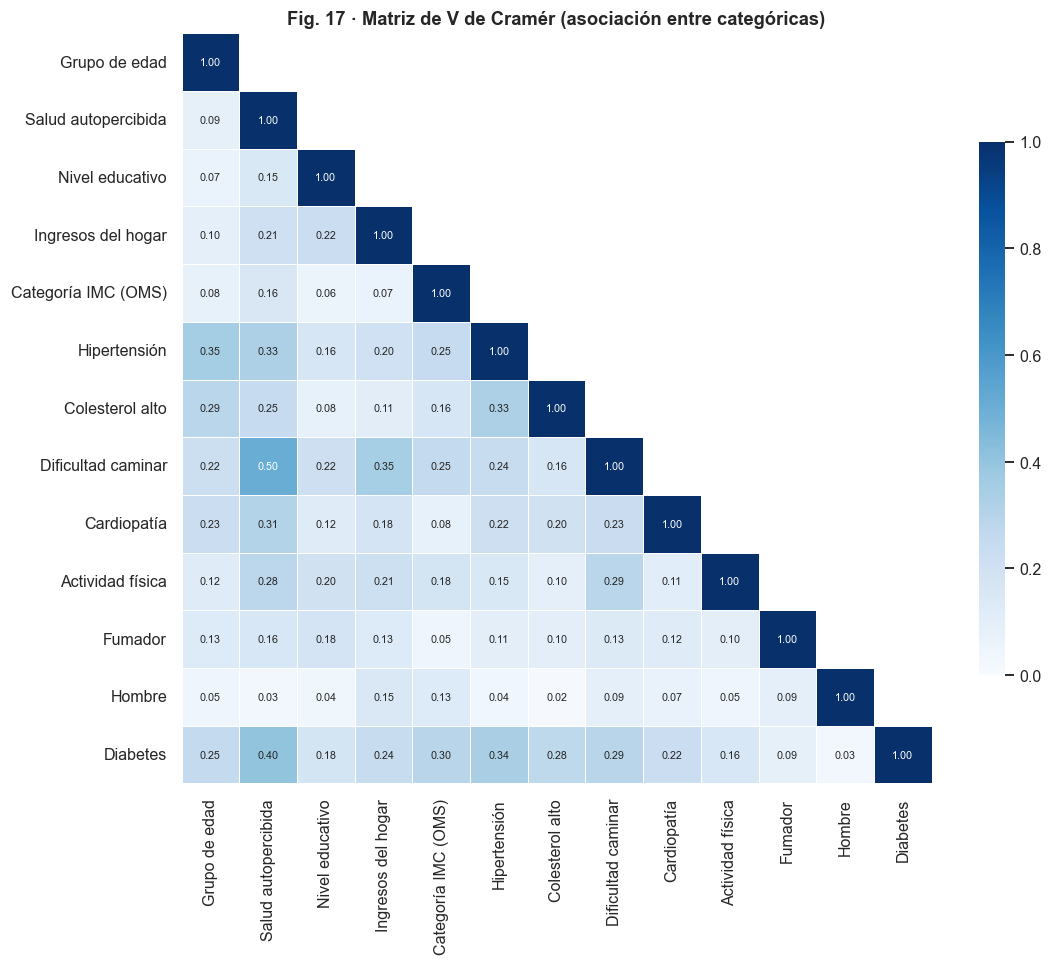

In [28]:
categoricas = ["grupo_edad", "salud_general", "nivel_educativo", "nivel_ingresos", "imc_categoria", "presion_alta", "colesterol_alto",
               "dificultad_caminar", "enfermedad_cardiaca", "actividad_fisica", "fumador", "es_hombre", "diabetes"]
cramer = eu.matriz_cramers_v(datos, categoricas).rename(index=NOMBRES, columns=NOMBRES)
fig, ax = plt.subplots(figsize=(11, 9))
eu.heatmap_correlacion(cramer, ax, "Fig. 17 · Matriz de V de Cramér (asociación entre categóricas)", vmin=0, cmap=eu.CMAP_SECUENCIAL)
eu.guardar_figura(fig, "fig17_cramers_v")
plt.show()

### 8.2 Multicolinealidad (VIF)
El factor de inflación de la varianza mide cuánto se explica cada predictor a partir del resto. VIF > 5 indica colinealidad preocupante para modelos lineales (inestabilidad de coeficientes).

In [29]:
def calcular_vif(columnas):
    X = datos[columnas].fillna(datos[columnas].median())
    X = ((X - X.mean()) / X.std()).assign(const=1.0)
    with np.errstate(divide="ignore"):
        return pd.Series([variance_inflation_factor(X.values, i) for i in range(len(columnas))], index=columnas, name="VIF")


vars_originales = [c for c in datos.columns if c not in ("diabetes", "dias_salud_fisica_mala", *pp.COLS_FEATURES_NUEVAS_ORD)]
vif = calcular_vif(vars_originales).sort_values(ascending=False)
vif_con_imc_cat = calcular_vif(vars_originales + ["imc_categoria"])
print(f"VIF máximo entre los predictores originales: {vif.max():.2f} ({vif.idxmax()})")
print(f"Al añadir imc_categoria → VIF(imc) = {vif_con_imc_cat['imc']:.1f}, VIF(imc_categoria) = {vif_con_imc_cat['imc_categoria']:.1f}")
print("n_factores_riesgo_cv es la suma exacta de 5 binarias → VIF = ∞ por construcción si se incluye junto a ellas")
vif.rename(index=NOMBRES).to_frame().style.format("{:.2f}").background_gradient(cmap="Reds", vmin=1, vmax=5)

VIF máximo entre los predictores originales: 1.66 (salud_general)
Al añadir imc_categoria → VIF(imc) = 6.1, VIF(imc_categoria) = 6.2
n_factores_riesgo_cv es la suma exacta de 5 binarias → VIF = ∞ por construcción si se incluye junto a ellas


,VIF
Salud autopercibida,1.66
Dificultad caminar,1.47
Ingresos del hogar,1.46
Hipertensión,1.36
Nivel educativo,1.31
Grupo de edad,1.31
Colesterol alto,1.21
Días salud mental mala,1.20
Cardiopatía,1.19
Actividad física,1.18


### 8.3 Interacciones relevantes

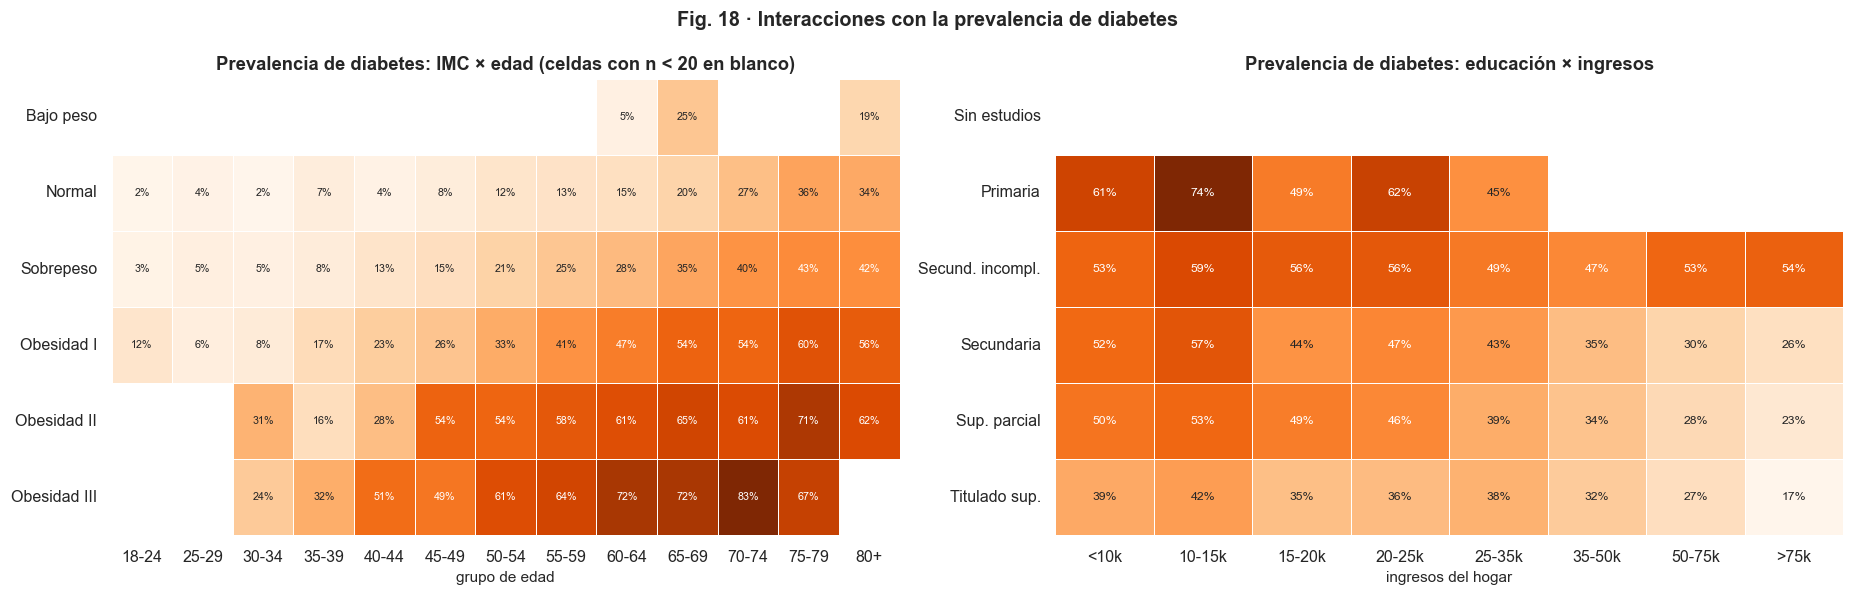

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(17, 5.5))

tab = datos.pivot_table(index="imc_categoria", columns="grupo_edad", values="diabetes", aggfunc="mean")
n = datos.pivot_table(index="imc_categoria", columns="grupo_edad", values="diabetes", aggfunc="count")
tab = tab.where(n >= 20)
tab.index = [pp.CATEGORIAS_IMC[int(i)].split(" (")[0] for i in tab.index]
tab.columns = [ETQ["grupo_edad"][int(c)] for c in tab.columns]
sns.heatmap(tab, annot=True, fmt=".0%", cmap="Oranges", ax=axes[0], cbar=False, annot_kws={"size": 7}, linewidths=0.5, linecolor="white")
axes[0].grid(False)
axes[0].set_title("Prevalencia de diabetes: IMC × edad (celdas con n < 20 en blanco)")
axes[0].set_xlabel("grupo de edad")
axes[0].set_ylabel("")

tab2 = datos.pivot_table(index="nivel_educativo", columns="nivel_ingresos", values="diabetes", aggfunc="mean")
n2 = datos.pivot_table(index="nivel_educativo", columns="nivel_ingresos", values="diabetes", aggfunc="count")
tab2 = tab2.where(n2 >= 20)
tab2.index = [ETQ["nivel_educativo"][int(i)] for i in tab2.index]
tab2.columns = [ETQ["nivel_ingresos"][int(c)] for c in tab2.columns]
sns.heatmap(tab2, annot=True, fmt=".0%", cmap="Oranges", ax=axes[1], cbar=False, annot_kws={"size": 8}, linewidths=0.5, linecolor="white")
axes[1].grid(False)
axes[1].set_title("Prevalencia de diabetes: educación × ingresos")
axes[1].set_xlabel("ingresos del hogar")
axes[1].set_ylabel("")
fig.suptitle("Fig. 18 · Interacciones con la prevalencia de diabetes")
fig.tight_layout()
eu.guardar_figura(fig, "fig18_interacciones")
plt.show()

**Hallazgos**
- Entre los predictores originales las correlaciones son **moderadas como máximo**: salud autopercibida–días de mala salud física (ρ = 0,50), salud autopercibida–dificultad para caminar (ρ = 0,46; V = 0,50) y educación–ingresos (ρ = 0,46). Las correlaciones de 0,70 y 0,69 de `n_factores_riesgo_cv` con hipertensión y colesterol son **por construcción**.
- **No hay multicolinealidad problemática** entre los predictores originales (VIF máx. = 1,7, muy por debajo de 5). Las variables derivadas sí son redundantes con sus componentes (`imc`/`imc_categoria` VIF ≈ 6; `n_factores_riesgo_cv` combinación lineal exacta). Decisión: en **modelos lineales** se usará *o* la variable derivada *o* sus componentes, no ambas; en modelos de árboles da igual.
- **Interacción IMC × edad**: ambos efectos se suman y se refuerzan. Con peso normal la prevalencia va del 2 % (18–24) al 36 % (75–79); con obesidad III supera el 70 % desde los 60 años. Los modelos basados en árboles capturan esto de forma natural; para modelos lineales podría añadirse un término de interacción.
- **Interacción educación × ingresos**: en los niveles educativos altos los ingresos marcan un gradiente claro (titulados: del 39 % al 17 %), pero con "secundaria incompleta" la prevalencia se queda en torno al 50–55 % sea cual sea la renta. Ambas variables aportan información parcialmente distinta, así que se mantienen las dos.
- La fuerte relación `salud_general` ↔ `dias_salud_fisica_mala` refleja un **constructo común** (estado de salud percibido) y no una fuga: ambas son respuestas de la misma encuesta y estarán disponibles al predecir.

<a id="9"></a>
## 9. Exploración orientada a clustering

El objetivo de negocio es obtener **perfiles explicables en una frase**. Para ello se propone clusterizar sobre un subconjunto de variables de **salud y hábitos** (`pp.COLS_CLUSTERING`) y reservar las sociodemográficas (sexo, educación, ingresos) para **describir** los clústeres a posteriori. Antes de modelar, exploramos si existe estructura y qué variables la dominan.

Variables de clustering: imc, dias_salud_fisica_mala, dias_salud_mental_mala, grupo_edad, salud_general, presion_alta, colesterol_alto, diabetes, enfermedad_cardiaca, dificultad_caminar, actividad_fisica, fumador


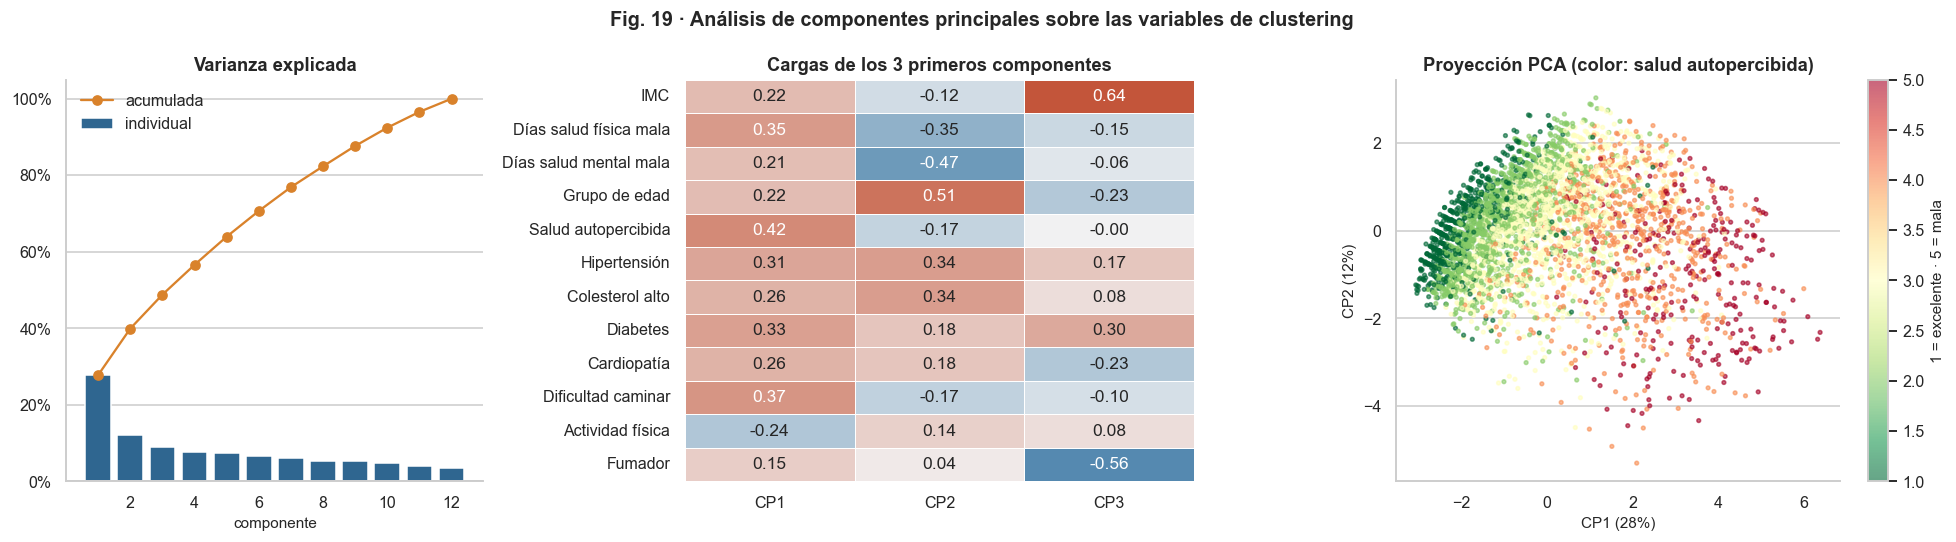

Varianza acumulada por los 2, 3 y 5 primeros componentes: 40%, 49%, 64%


In [31]:
pre_clu = pp.construir_preprocesador("clustering")
X_clu = pre_clu.fit_transform(crudo)  # imputación + estandarización (exploratorio, con todos los datos)
print("Variables de clustering:", ", ".join(X_clu.columns))

pca = PCA(random_state=pp.SEMILLA).fit(X_clu)
Z = pca.transform(X_clu)
var_exp = pca.explained_variance_ratio_

fig, axes = plt.subplots(1, 3, figsize=(18, 5), gridspec_kw={"width_ratios": [0.9, 1.1, 1.2]})
axes[0].bar(range(1, len(var_exp) + 1), var_exp, color=eu.AZUL, label="individual")
axes[0].plot(range(1, len(var_exp) + 1), np.cumsum(var_exp), "o-", color=eu.NARANJA, label="acumulada")
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
axes[0].set_xlabel("componente")
axes[0].set_title("Varianza explicada")
axes[0].legend()

cargas = pd.DataFrame(pca.components_[:3].T, index=[NOMBRES.get(c, c) for c in X_clu.columns], columns=["CP1", "CP2", "CP3"])
sns.heatmap(cargas, annot=True, fmt=".2f", cmap=eu.CMAP_DIVERGENTE, center=0, ax=axes[1], cbar=False, linewidths=0.5, linecolor="white")
axes[1].grid(False)
axes[1].set_title("Cargas de los 3 primeros componentes")

muestra = np.random.default_rng(pp.SEMILLA).choice(len(Z), 4000, replace=False)
sc = axes[2].scatter(Z[muestra, 0], Z[muestra, 1], c=datos["salud_general"].fillna(3).to_numpy()[muestra], cmap="RdYlGn_r", s=6, alpha=0.6)
axes[2].set_xlabel(f"CP1 ({var_exp[0]:.0%})")
axes[2].set_ylabel(f"CP2 ({var_exp[1]:.0%})")
axes[2].set_title("Proyección PCA (color: salud autopercibida)")
plt.colorbar(sc, ax=axes[2], label="1 = excelente · 5 = mala")
fig.suptitle("Fig. 19 · Análisis de componentes principales sobre las variables de clustering")
fig.tight_layout()
eu.guardar_figura(fig, "fig19_pca")
plt.show()
print("Varianza acumulada por los 2, 3 y 5 primeros componentes:", ", ".join(f"{v:.0%}" for v in np.cumsum(var_exp)[[1, 2, 4]]))

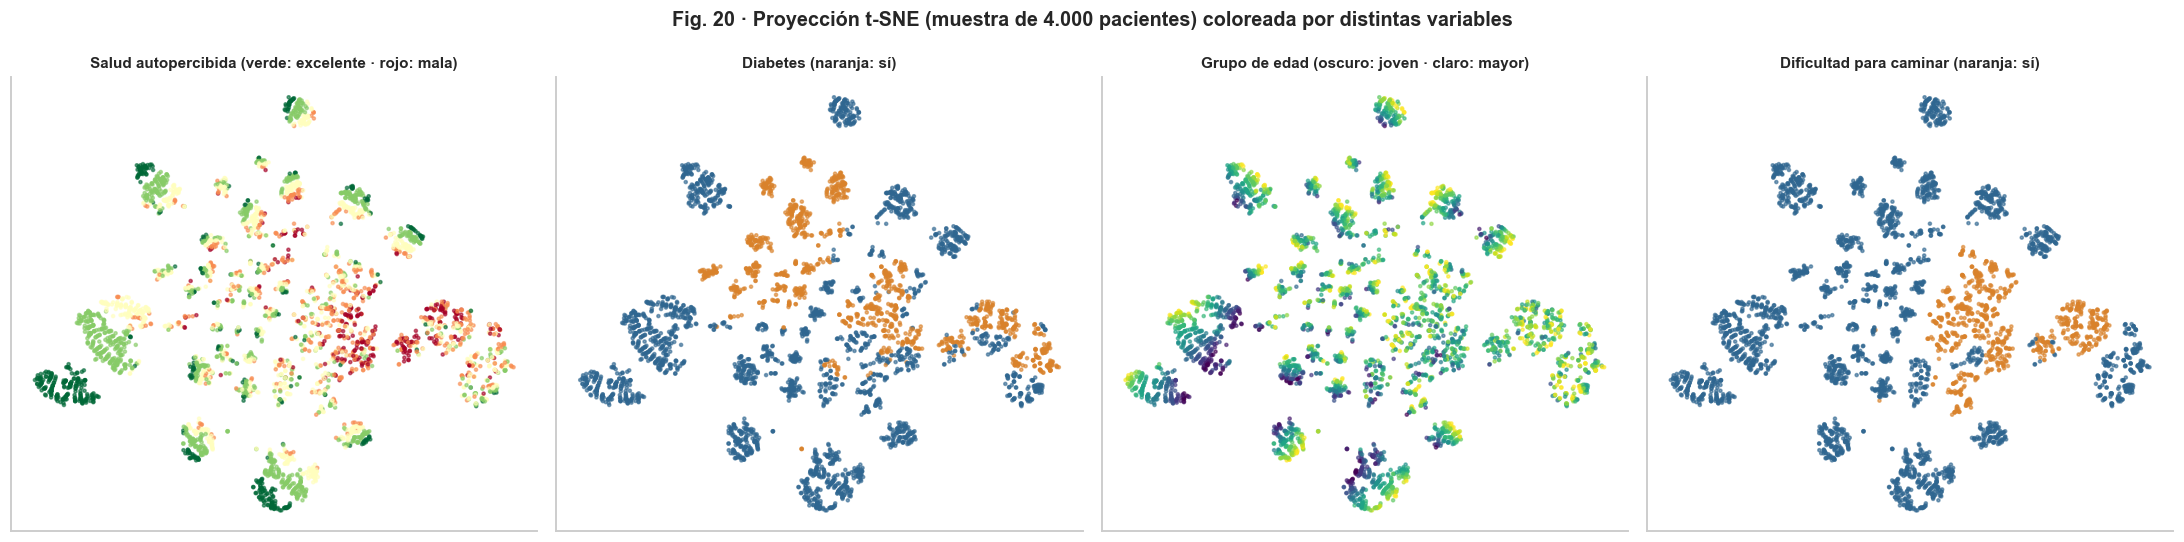

In [32]:
tsne = TSNE(n_components=2, perplexity=40, init="pca", random_state=pp.SEMILLA)
emb = tsne.fit_transform(X_clu.iloc[muestra])

colorear = {"Salud autopercibida (verde: excelente · rojo: mala)": ("salud_general", "RdYlGn_r"),
            "Diabetes (naranja: sí)": ("diabetes", None),
            "Grupo de edad (oscuro: joven · claro: mayor)": ("grupo_edad", "viridis"),
            "Dificultad para caminar (naranja: sí)": ("dificultad_caminar", None)}
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax, (titulo, (col, cmap)) in zip(axes, colorear.items()):
    valores = datos[col].fillna(datos[col].median()).to_numpy()[muestra]
    if cmap is None:
        ax.scatter(emb[:, 0], emb[:, 1], c=np.where(valores == 1, eu.NARANJA, eu.AZUL), s=4, alpha=0.6)
    else:
        ax.scatter(emb[:, 0], emb[:, 1], c=valores, cmap=cmap, s=4, alpha=0.6)
    ax.set_title(titulo, fontsize=10)
    ax.grid(False)
    ax.set_xticks([])
    ax.set_yticks([])
fig.suptitle("Fig. 20 · Proyección t-SNE (muestra de 4.000 pacientes) coloreada por distintas variables")
fig.tight_layout()
eu.guardar_figura(fig, "fig20_tsne")
plt.show()

**Hallazgos**
- **CP1 (28 % de la varianza) = "carga de enfermedad"**: cargan en positivo la salud autopercibida, la dificultad para caminar, los días de mala salud física, la diabetes y la hipertensión, y en negativo la actividad física. En la proyección se ve un gradiente limpio de verde (salud excelente) a rojo (mala).
- **CP2 (12 %) = edad cardiometabólica frente a malestar**: opone a pacientes **mayores con hipertensión y colesterol** a pacientes **más jóvenes con muchos días de mala salud mental y física**. Es un eje con mucho sentido clínico para programas de prevención distintos.
- **CP3 (9 %)**: IMC y diabetes frente a tabaquismo.
- La varianza está **repartida** (2 componentes = 40 %, 5 = 64 %) y la nube del PCA es un **continuo** sin grupos separados. Los clústeres serán, por tanto, una **segmentación útil de un continuo**: se valorarán por interpretabilidad y estabilidad más que por métricas de compacidad (como pide el enunciado).
- Las "islas" del t-SNE no son grupos naturales: se corresponden con **combinaciones de las variables binarias** (diabetes, dificultad para caminar…), que al estandarizarse dominan las distancias euclídeas. Implicaciones para la fase de modelado: limitar el nº de binarias o resumirlas en índices, o usar métricas para datos mixtos (**Gower + k-medoids / k-prototypes**, clustering jerárquico) y comparar con K-means sobre las variables estandarizadas.
- Las variables sociodemográficas (sexo, educación, ingresos) se reservan para **describir** los perfiles a posteriori, para que los grupos se formen por estado de salud y no por renta.

<a id="10"></a>
## 10. Conclusiones y decisiones de preprocesado

| # | Hallazgo del EDA | Decisión | Justificación |
|---|---|---|---|
| 1 | 7 columnas PII ofuscadas, un valor distinto por fila | **Eliminar** | Sin poder predictivo y sujetas a protección de datos |
| 2 | `usuario_alta_datos` independiente de ambos objetivos (V ≈ 0) | **Eliminar** | Columna de gestión, ni señal ni riesgo de fuga |
| 3 | `id_paciente_proy` | Usar como **índice**, nunca como feature | Permite trazar registros sin que el modelo memorice IDs |
| 4 | 4 binarias con hasta 8 codificaciones | **Unificar a 0/1** (`normalizar_binaria`), valores irreconocibles → nulo | Correspondencia inequívoca; robustez ante datos nuevos en la API |
| 5 | Ordinales con gradientes monótonos con ambos objetivos | **Codificación ordinal** (enteros) | Conserva el orden con una sola columna; evita *one-hot* innecesario |
| 6 | `sexo` binaria en texto | `es_hombre` (0/1) | Formato numérico homogéneo |
| 7 | 8 % de filas con nulos: un bloque de hábitos (376) y un patrón anidado de abandono (267 ⊂ 397 ⊂ 657), compatibles con MCAR | **Imputar** (mediana / moda) dentro del pipeline, ajustado solo en train, + indicadores `falta_habitos` y `falta_imc` | No se pierde muestra y la API siempre responde; sin fuga train → test |
| 8 | IMC asimétrico con outliers clínicamente reales | **Conservar** los valores; imputar con la mediana; añadir `imc_categoria` (OMS) | Los extremos son informativos para la diabetes; la categoría facilita interpretar clústeres |
| 9 | Factores de riesgo CV muy asociados a diabetes | Variable derivada **`n_factores_riesgo_cv`** | Resume el riesgo cardiometabólico (V = 0,38) |
| 10 | Escalas distintas (IMC, días, ordinales) | **Estandarizar** numéricas y ordinales; en clustering también binarias | Necesario para modelos lineales, distancias y regularización |
| 11 | `diabetes` remuestreada al 33 % | Partición **estratificada**; probabilidades no poblacionales | Mantener proporciones en train/test; limitación a reportar |
| 12 | `dias_salud_fisica_mala` cero-inflada y bimodal | Partición estratificada por tramos **0 / 1–29 / 30**; métrica MAE | Conservar la forma de la distribución; métrica robusta |
| 13 | Sin multicolinealidad entre originales (VIF ≤ 1,7); derivadas redundantes con sus componentes | Se conservan todas; en modelos lineales, usar derivada **o** componentes | Evitar coeficientes inestables sin perder información para árboles |
| 14 | Clustering: continuo con ejes de "carga de enfermedad" y "edad cardiometabólica vs malestar"; binarias dominan distancias | Clusterizar con variables de salud y hábitos; sociodemográficas solo para describir; comparar métricas para datos mixtos | Perfiles accionables y explicables en una frase |

### Variables por línea de trabajo (primera propuesta, se refinará en el modelado)
- **Clasificación (`diabetes`)**: todos los predictores limpios + variables derivadas (23 columnas).
- **Regresión (`dias_salud_fisica_mala`)**: todos los predictores limpios + derivadas, incluida `diabetes` como entrada (23 columnas).
- **Clustering**: 12 variables de salud y hábitos (`pp.COLS_CLUSTERING`).

### Limitaciones a recoger en el informe
- **Remuestreo de `diabetes`**: las cifras no permiten lecturas epidemiológicas y las probabilidades del clasificador no son poblacionales.
- **Autorreporte**: diagnósticos, hábitos y días de mala salud son declarados por el paciente (sesgo de recuerdo, deseabilidad social, *heaping*).
- **Diseño transversal**: las asociaciones encontradas no son causales (p. ej. alcohol ↔ diabetes).
- **Sesgo de no respuesta**: aunque los nulos parecen MCAR respecto a las variables observadas, no puede descartarse que dependan de variables no recogidas.

➡️ El preprocesado se implementa en `src/preprocesamiento.py` y se ejecuta en `02_preprocesado.ipynb`.